# CS675 – Project 3: Time Series Forecasting with Facebook Prophet

In [ ]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

In [ ]:
df = pd.read_csv('Electric_Consumption_And_Cost__2010_-_Feb_2025__20250428.csv', low_memory=False)
print("Dataset Shape:", df.shape)
print("Dataset Description:\n", df.describe())  # Summarize dataset

Dataset Shape: (521035, 27)
Dataset Description:
                TDS #            EDP  UMIS BILL ID         # days  \
count  519157.000000  521035.000000  5.210350e+05  521027.000000   
mean      116.499202     424.929924  7.480257e+06      30.361547   
std       128.773830     186.993741  4.033719e+06       2.596024   
min         0.000000      63.000000  1.726303e+06    -335.000000   
25%        33.000000     225.000000  3.788160e+06      29.000000   
50%        63.000000     426.000000  6.542550e+06      30.000000   
75%       145.000000     552.000000  1.095094e+07      31.000000   
max       582.000000     999.000000  1.488953e+07     749.000000   

       Current Charges  Consumption (KWH)    KWH Charges  Consumption (KW)  \
count    521035.000000       5.210350e+05  521035.000000     521035.000000   
mean       4284.955086       3.046078e+04    1433.879714         61.430595   
std        6210.140634       4.850114e+04    2463.710587        530.949951   
min      -25622.210000   

## Task 1: Data Preprocessing and Time Unit Detection

In [ ]:
print("\nStep 2: Convert 'Service End Date' to datetime and keep relevant columns...")
df = df[['Service End Date', 'Consumption (KWH)']].dropna()
df['Service End Date'] = pd.to_datetime(df['Service End Date'], errors='coerce')
df = df.rename(columns={'Service End Date': 'ds', 'Consumption (KWH)': 'y'})
df = df.dropna()
print(f"Rows after dropping nulls: {df.shape[0]}")
print(df.head(), "\n")

print("Step 3: Aggregate consumption at daily level...")
df = df.groupby('ds').sum().reset_index()
print(f"Aggregated daily data. Sample:")
print(df.head(), "\n")

print("Step 4: Automatically detect the time unit...")

def detect_time_unit(df):
    delta_days = df['ds'].diff().dropna().dt.days
    avg_delta = np.mean(delta_days)
    print(f"Average gap between dates: {avg_delta:.2f} days")

    if avg_delta < 2:
        return 'D'
    elif avg_delta < 28:
        return 'M'
    else:
        return 'Y'

time_unit = detect_time_unit(df)
print(f"Detected Time Unit: {time_unit} (D=Day, M=Month, Y=Year)")

print("Step 5: Resample if necessary...")
if time_unit == 'ME':
    df = df.resample('ME', on='ds').sum().reset_index()
elif time_unit == 'Y':
    df = df.resample('Y', on='ds').sum().reset_index()
print("\nFinal prepared data sample:")
print(df.head())


Step 2: Convert 'Service End Date' to datetime and keep relevant columns...
Rows after dropping nulls: 521027
          ds         y
0 2010-01-26  128800.0
1 2010-02-25  115200.0
2 2010-03-26  103200.0
3 2010-04-26  105600.0
4 2010-05-24   97600.0 

Step 3: Aggregate consumption at daily level...
Aggregated daily data. Sample:
          ds            y
0 2010-01-20         33.0
1 2010-01-26  106279420.0
2 2010-01-28      18720.0
3 2010-01-29         93.0
4 2010-02-19         29.0 

Step 4: Automatically detect the time unit...
Average gap between dates: 5.20 days
Detected Time Unit: M (D=Day, M=Month, Y=Year)
Step 5: Resample if necessary...

Final prepared data sample:
          ds            y
0 2010-01-20         33.0
1 2010-01-26  106279420.0
2 2010-01-28      18720.0
3 2010-01-29         93.0
4 2010-02-19         29.0


## Task 2: Train and Forecast with FBProphet

Step 6: Set forecast periods based on time unit...
Forecast periods: [1, 6, 9]
Step 7: Train Prophet model...


DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/7cdi8aop.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/q66r92n1.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=56168', 'data', 'file=/tmp/tmp4ptzph50/7cdi8aop.json', 'init=/tmp/tmp4ptzph50/q66r92n1.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model79pssac0/prophet_model-20250509194455.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:55 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:55 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


 Model trained.
Forecasting 1 M into the future...


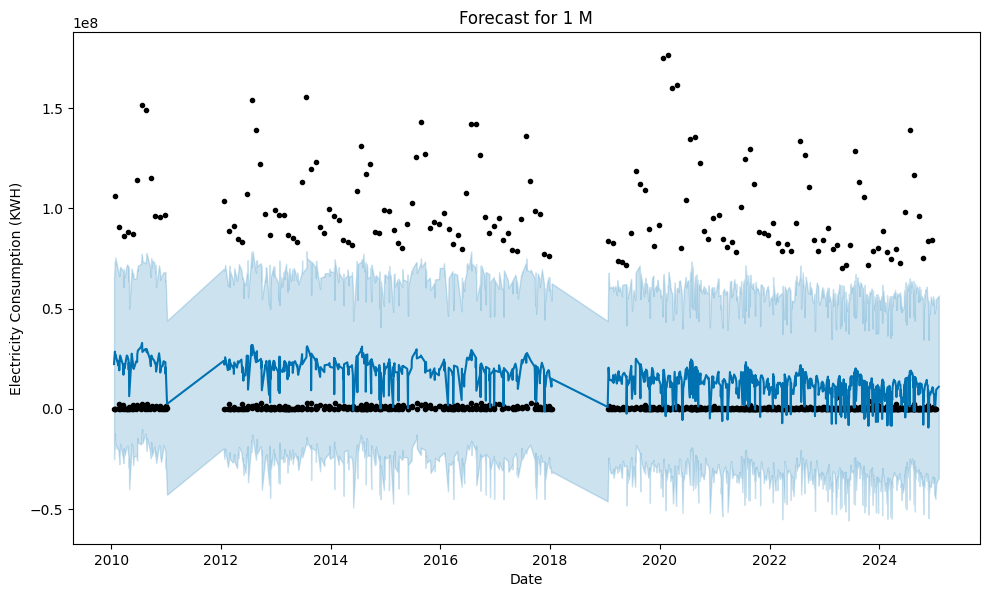

Forecast Table:
             ds          yhat    yhat_lower    yhat_upper
1053 2025-01-31  1.095840e+07 -3.431957e+07  5.643242e+07 

Forecasting 6 M into the future...


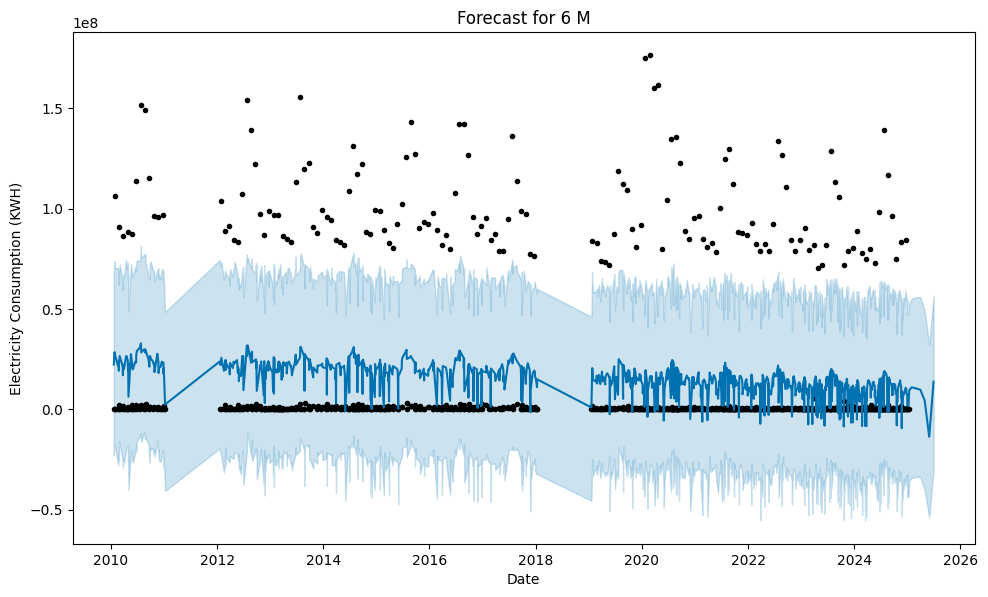

Forecast Table:
             ds          yhat    yhat_lower    yhat_upper
1053 2025-01-31  1.095840e+07 -3.420715e+07  5.518404e+07
1054 2025-02-28  1.044102e+07 -3.368600e+07  5.586610e+07
1055 2025-03-31  9.786377e+06 -3.372214e+07  5.593986e+07
1056 2025-04-30  4.372589e+06 -4.041503e+07  4.893215e+07
1057 2025-05-31 -1.367931e+07 -5.389558e+07  3.231208e+07
1058 2025-06-30  1.374555e+07 -3.005070e+07  5.653401e+07 

Forecasting 9 M into the future...


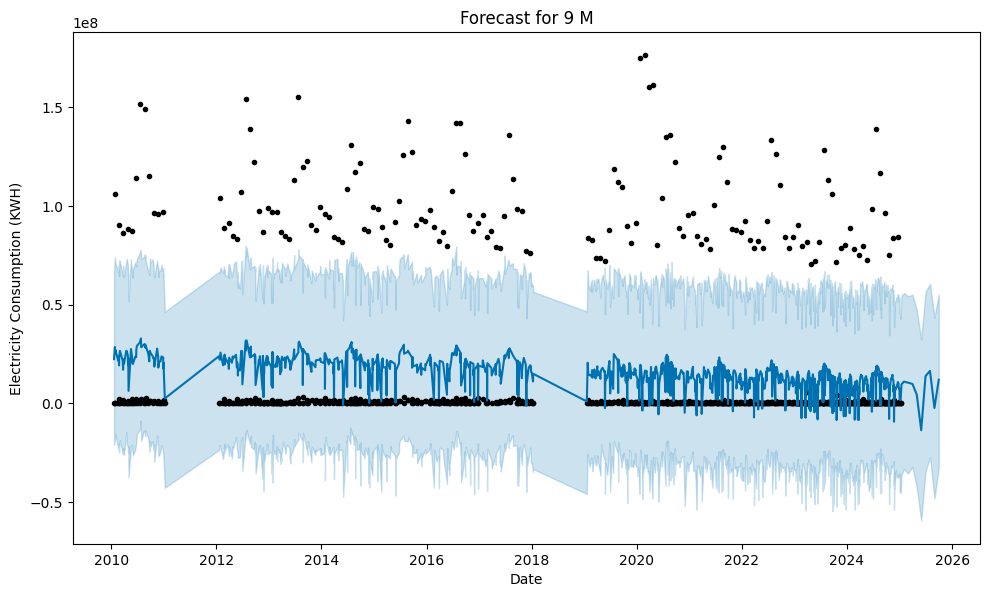

Forecast Table:
             ds          yhat    yhat_lower    yhat_upper
1053 2025-01-31  1.095840e+07 -3.327568e+07  5.589399e+07
1054 2025-02-28  1.044102e+07 -3.560912e+07  5.420982e+07
1055 2025-03-31  9.786377e+06 -3.226883e+07  5.503022e+07
1056 2025-04-30  4.372589e+06 -4.276754e+07  4.724331e+07
1057 2025-05-31 -1.367931e+07 -5.942591e+07  3.234647e+07
1058 2025-06-30  1.374555e+07 -3.467915e+07  5.642581e+07
1059 2025-07-31  1.641008e+07 -2.742349e+07  6.052628e+07
1060 2025-08-31 -2.393283e+06 -4.832755e+07  4.346944e+07
1061 2025-09-30  1.192388e+07 -3.264923e+07  5.521256e+07 



In [ ]:
# Define time_unit as 'D', 'M', or 'Y' somewhere in your code
# e.g., time_unit = 'M'

print("Step 6: Set forecast periods based on time unit...")
forecast_periods = {'D': [100, 200, 365], 'M': [1, 6, 9], 'Y': [1, 10, 20]}[time_unit]
print(f"Forecast periods: {forecast_periods}")

print("Step 7: Train Prophet model...")
model = Prophet(growth='linear', daily_seasonality=False)
model.fit(df)
print(" Model trained.")

for period in forecast_periods:
    print(f"Forecasting {period} {time_unit} into the future...")

    # Change freq='M' to freq='ME' to avoid the deprecation warning
    future = model.make_future_dataframe(periods=period, freq='ME' if time_unit == 'M' else time_unit)
    forecast = model.predict(future)

    model.plot(forecast)
    plt.title(f'Forecast for {period} {time_unit}')
    plt.xlabel("Date")
    plt.ylabel("Electricity Consumption (KWH)")
    plt.grid()
    plt.show()

    print("Forecast Table:")
    print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(period), "\n")


## ⚙️ Task 3: Parameter Tuning

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/bvx0cfym.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/321ggbue.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=72038', 'data', 'file=/tmp/tmp4ptzph50/bvx0cfym.json', 'init=/tmp/tmp4ptzph50/321ggbue.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelmodvgcqc/prophet_model-20250509194456.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:56 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:56 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


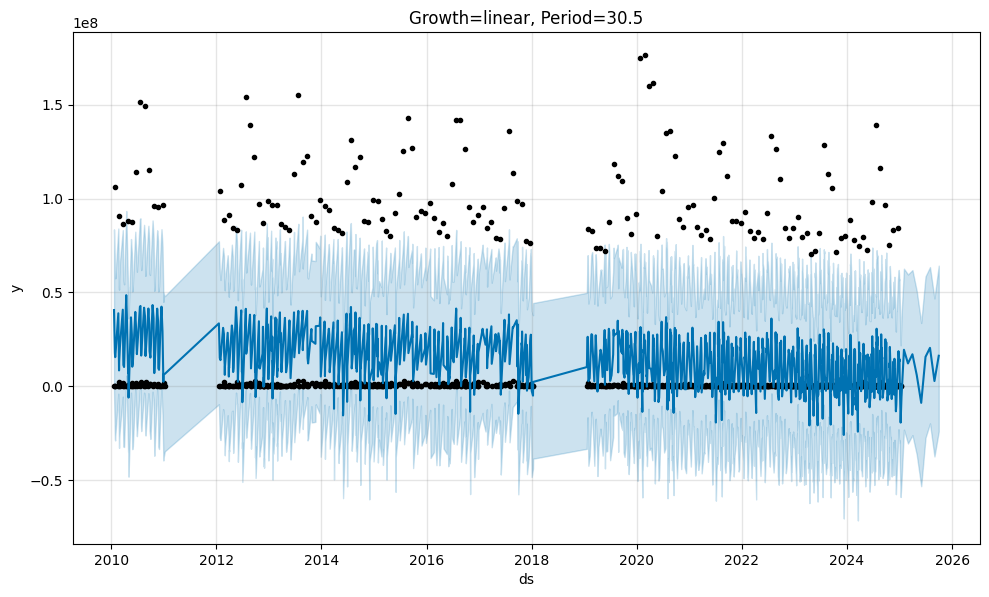

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/tecmyhk_.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/sbrsnvvp.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=76135', 'data', 'file=/tmp/tmp4ptzph50/tecmyhk_.json', 'init=/tmp/tmp4ptzph50/sbrsnvvp.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model9u6jo8tn/prophet_model-20250509194457.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:57 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:57 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


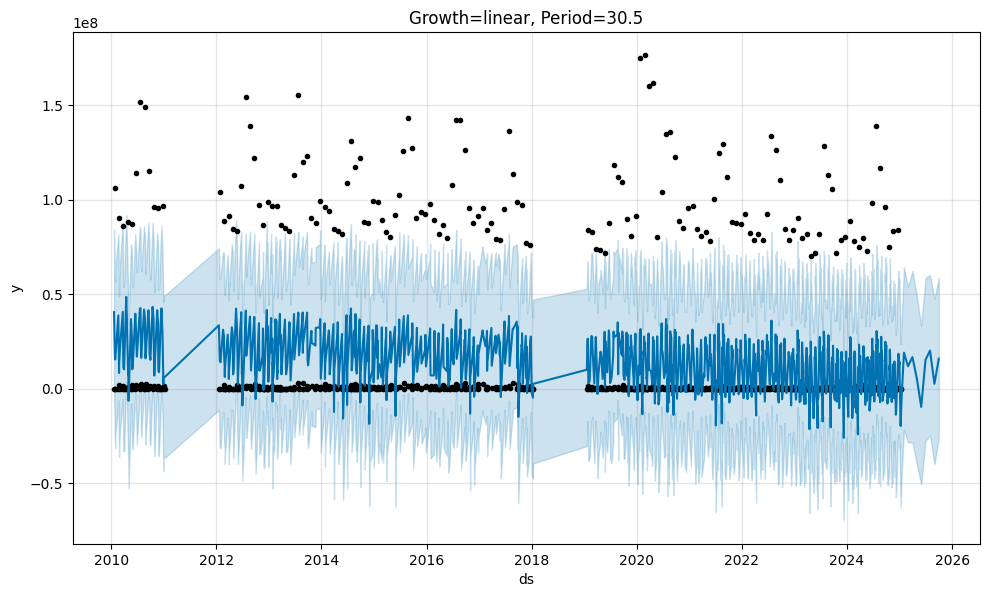

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/vghl25na.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/vnx03gf2.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=18504', 'data', 'file=/tmp/tmp4ptzph50/vghl25na.json', 'init=/tmp/tmp4ptzph50/vnx03gf2.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modeld4smedhw/prophet_model-20250509194457.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:57 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:57 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


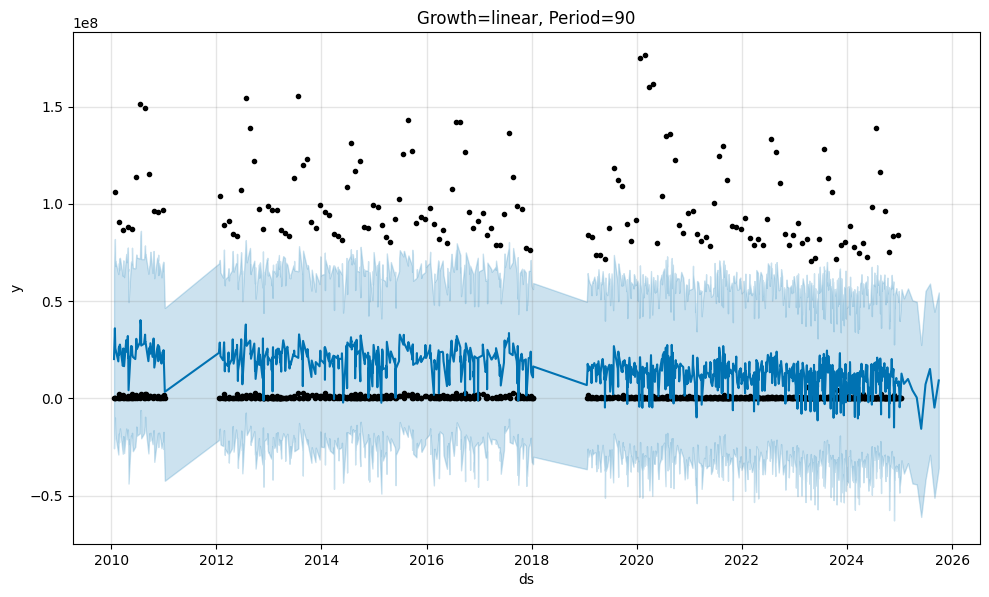

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/iwgr1ths.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/6o624kae.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=4530', 'data', 'file=/tmp/tmp4ptzph50/iwgr1ths.json', 'init=/tmp/tmp4ptzph50/6o624kae.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelb04vfr7c/prophet_model-20250509194458.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:58 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


19:44:58 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


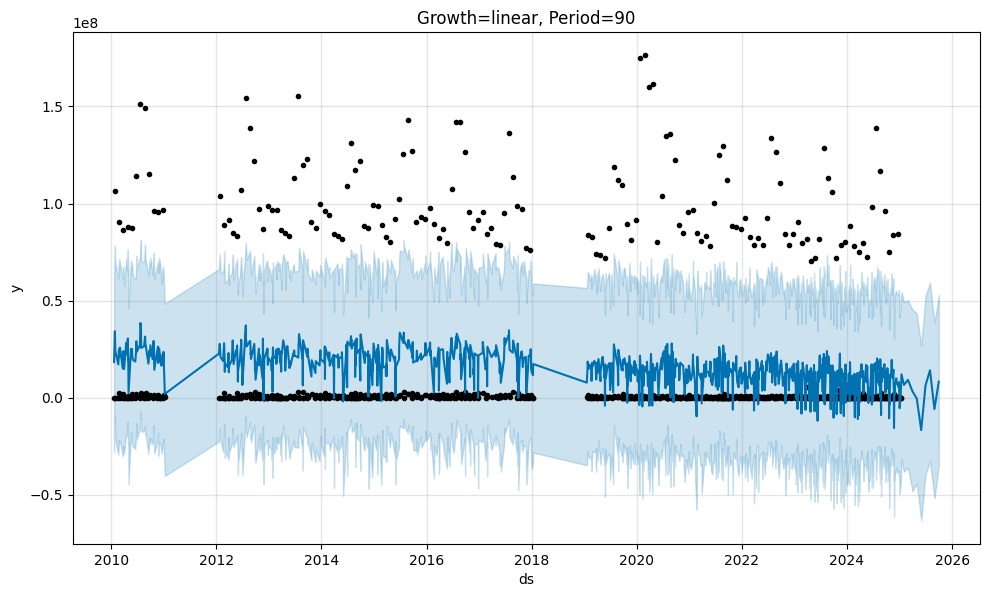

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/ao0wst19.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/2umtuewp.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=70198', 'data', 'file=/tmp/tmp4ptzph50/ao0wst19.json', 'init=/tmp/tmp4ptzph50/2umtuewp.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelvwczf1ww/prophet_model-20250509194458.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:58 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:59 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


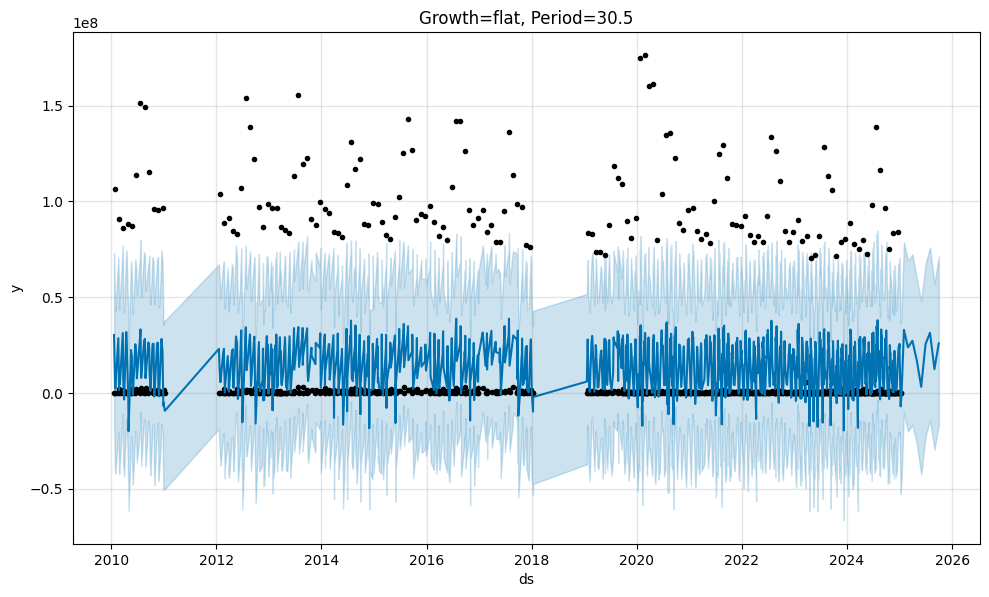

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/lwx7x0ly.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/q6n24w05.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=39147', 'data', 'file=/tmp/tmp4ptzph50/lwx7x0ly.json', 'init=/tmp/tmp4ptzph50/q6n24w05.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelc5y0b_fm/prophet_model-20250509194459.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:44:59 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:44:59 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


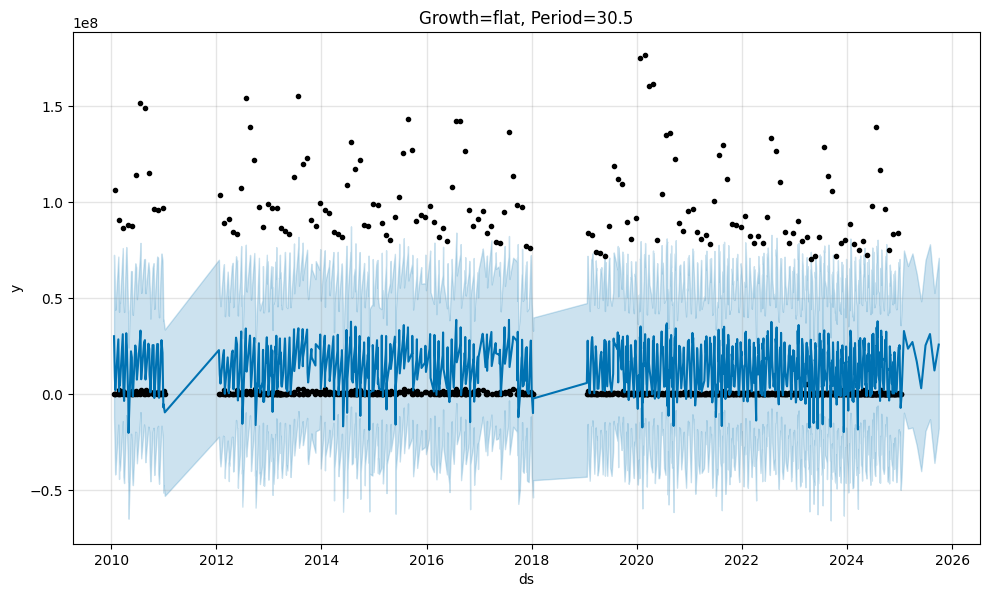

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/gjfl8r3o.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/rlrriqij.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=69673', 'data', 'file=/tmp/tmp4ptzph50/gjfl8r3o.json', 'init=/tmp/tmp4ptzph50/rlrriqij.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelgietn7xd/prophet_model-20250509194500.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:00 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:00 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


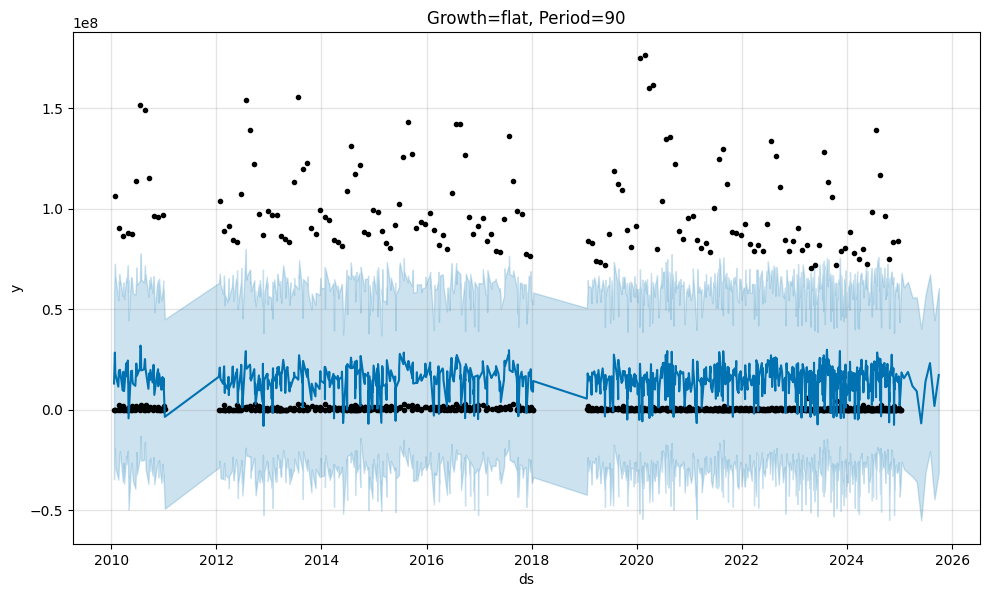

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/lm77lffl.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/vsw2y8cl.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=99691', 'data', 'file=/tmp/tmp4ptzph50/lm77lffl.json', 'init=/tmp/tmp4ptzph50/vsw2y8cl.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model4905usbg/prophet_model-20250509194500.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:00 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:00 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


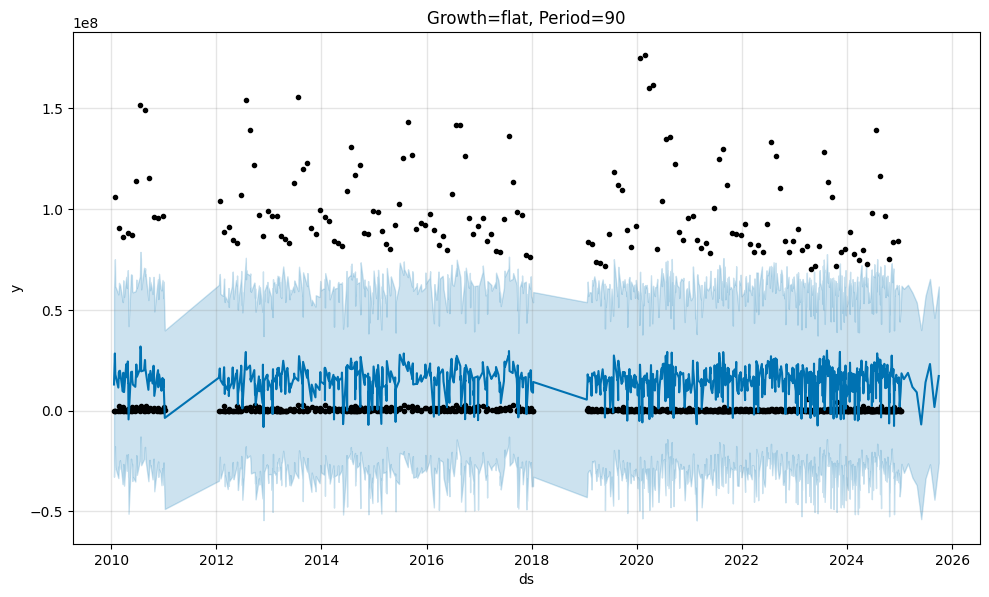

In [ ]:
growth_options = ['linear', 'flat']
seasonality_settings = [{'period': 30.5, 'fourier_order': 5}, {'period': 90, 'fourier_order': 10}]
changepoint_settings = [{'n_changepoints': 25, 'changepoint_prior_scale': 0.05}, {'n_changepoints': 50, 'changepoint_prior_scale': 0.1}]

for growth in growth_options:
    for seasonality in seasonality_settings:
        for changepoint in changepoint_settings:
            print(f"Model: Growth={growth}, Seasonality={seasonality}, Changepoints={changepoint}")
            model = Prophet(
                growth=growth,
                daily_seasonality=False,
                n_changepoints=changepoint['n_changepoints'],
                changepoint_prior_scale=changepoint['changepoint_prior_scale']
            )
            model.add_seasonality(name='custom', period=seasonality['period'], fourier_order=seasonality['fourier_order'])
            model.fit(df)

            # Change freq='M' to freq='ME' to avoid the deprecation warning when time_unit == 'M'
            future = model.make_future_dataframe(periods=max(forecast_periods), freq='ME' if time_unit == 'M' else time_unit)
            forecast = model.predict(future)

            model.plot(forecast)
            plt.title(f"Growth={growth}, Period={seasonality['period']}")
            plt.show()


DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/7zv79rpt.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/ix9hxcb3.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=9168', 'data', 'file=/tmp/tmp4ptzph50/7zv79rpt.json', 'init=/tmp/tmp4ptzph50/ix9hxcb3.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelmk5hpdkn/prophet_model-20250509194501.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:01 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:01 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Training model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


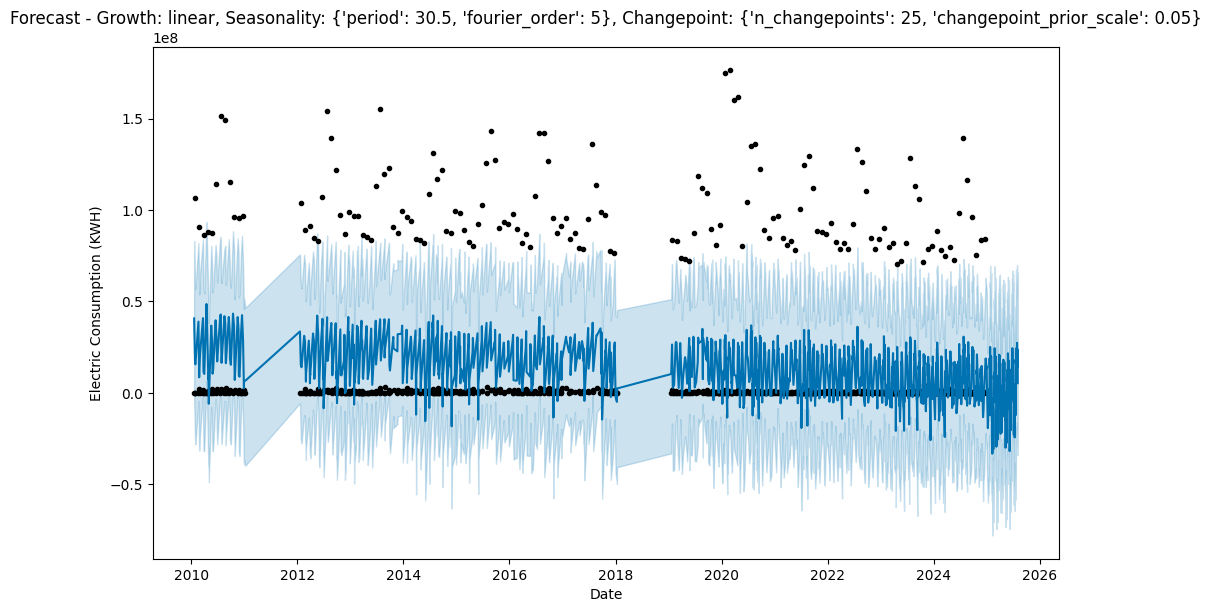

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/_tmyl8lx.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/6h1cs5ot.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=5221', 'data', 'file=/tmp/tmp4ptzph50/_tmyl8lx.json', 'init=/tmp/tmp4ptzph50/6h1cs5ot.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model27ccejnb/prophet_model-20250509194501.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:01 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:01 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.112311e+07 -2.445110e+07  6.174886e+07
1244 2025-07-25  2.456370e+07 -1.885712e+07  6.755677e+07
1245 2025-07-26  9.775369e+06 -3.178096e+07  5.145644e+07
1246 2025-07-27  1.258166e+07 -2.894334e+07  5.401345e+07
1247 2025-07-28  2.732099e+07 -1.618446e+07  6.997495e+07
1248 2025-07-29  2.062904e+07 -2.464973e+07  6.258791e+07
1249 2025-07-30  1.377104e+07 -3.039039e+07  6.141433e+07
1250 2025-07-31  2.051080e+07 -1.967069e+07  6.526284e+07
1251 2025-08-01  2.368410e+07 -2.185959e+07  6.572038e+07
1252 2025-08-02  5.258335e+06 -3.420475e+07  4.930392e+07
Training model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


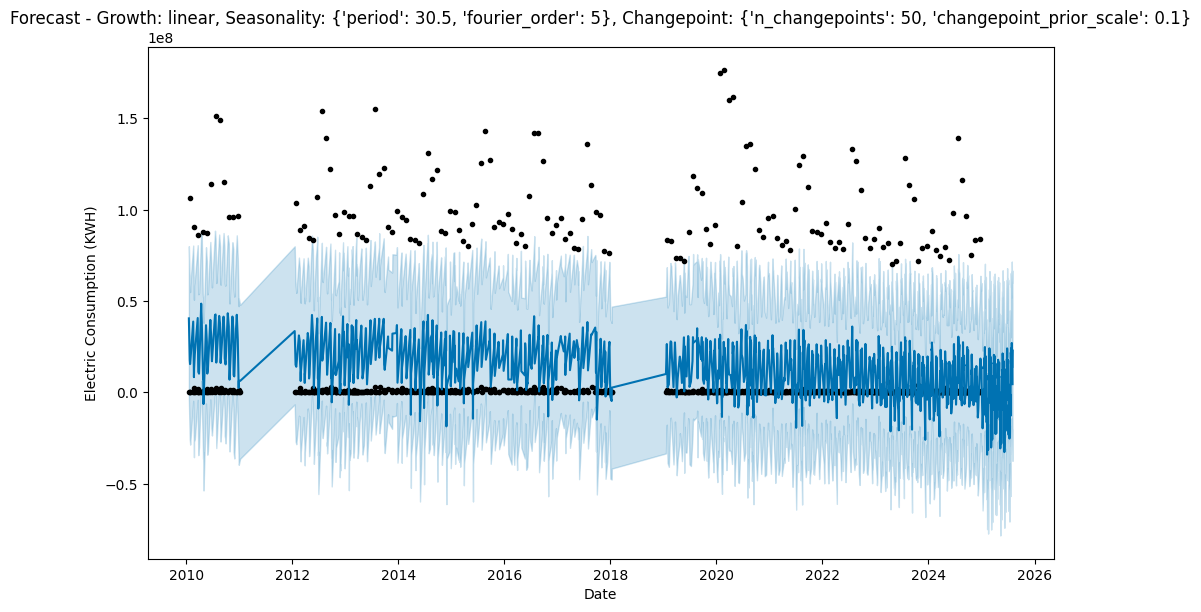

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/gt0xrxfp.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/4xixrdrl.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=82821', 'data', 'file=/tmp/tmp4ptzph50/gt0xrxfp.json', 'init=/tmp/tmp4ptzph50/4xixrdrl.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model0mpgkhn7/prophet_model-20250509194502.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:02 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:02 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.085504e+07 -2.292095e+07  6.634000e+07
1244 2025-07-25  2.430619e+07 -1.838739e+07  6.606925e+07
1245 2025-07-26  9.151387e+06 -3.334869e+07  5.211637e+07
1246 2025-07-27  1.252214e+07 -3.100280e+07  5.544802e+07
1247 2025-07-28  2.707999e+07 -1.414941e+07  7.168598e+07
1248 2025-07-29  2.036961e+07 -2.219018e+07  6.150989e+07
1249 2025-07-30  1.346898e+07 -3.181906e+07  5.989089e+07
1250 2025-07-31  2.019514e+07 -2.036615e+07  6.428143e+07
1251 2025-08-01  2.334845e+07 -2.039717e+07  6.678490e+07
1252 2025-08-02  4.541648e+06 -3.745319e+07  4.935541e+07
Training model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


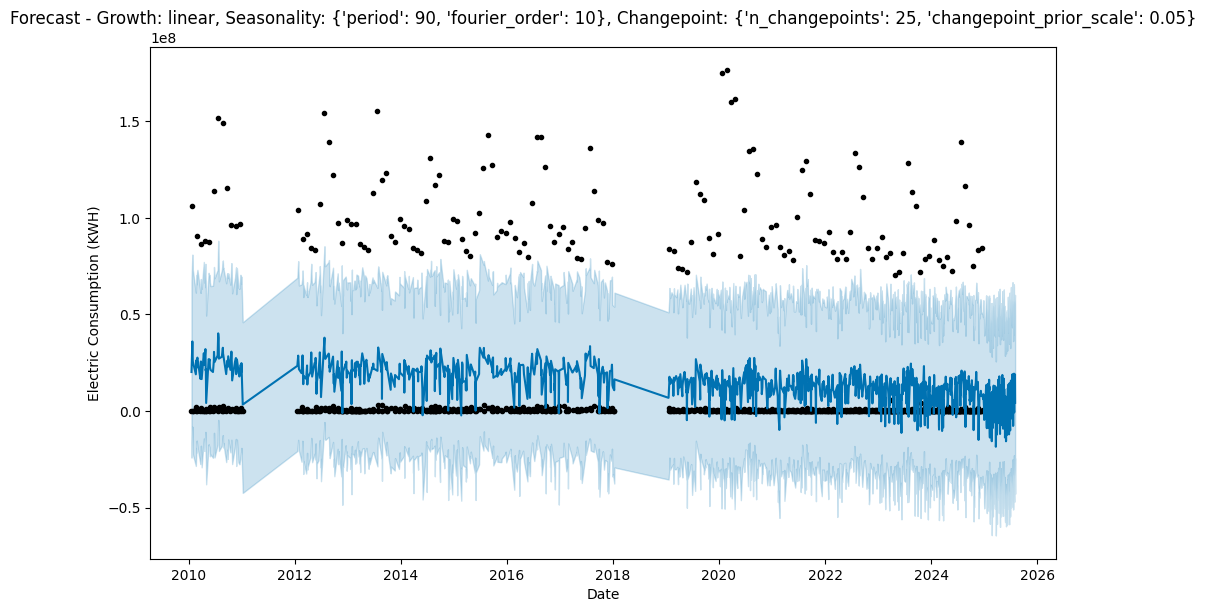

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/1v6z60yv.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/emhi4p1h.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=16360', 'data', 'file=/tmp/tmp4ptzph50/1v6z60yv.json', 'init=/tmp/tmp4ptzph50/emhi4p1h.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelw1tcvbob/prophet_model-20250509194502.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:02 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  1.790721e+07 -2.585583e+07  6.559477e+07
1244 2025-07-25  1.933091e+07 -2.291399e+07  6.398645e+07
1245 2025-07-26  7.120968e+05 -4.392479e+07  4.653489e+07
1246 2025-07-27 -7.120555e+05 -4.700003e+07  3.967805e+07
1247 2025-07-28  1.503979e+07 -2.875847e+07  5.526167e+07
1248 2025-07-29  1.426857e+07 -3.186237e+07  5.773704e+07
1249 2025-07-30  9.564312e+06 -3.368812e+07  5.549886e+07
1250 2025-07-31  1.509962e+07 -3.093300e+07  5.863818e+07
1251 2025-08-01  1.897234e+07 -2.434684e+07  6.010994e+07
1252 2025-08-02  4.276641e+06 -4.284818e+07  4.964675e+07
Training model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


19:45:02 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


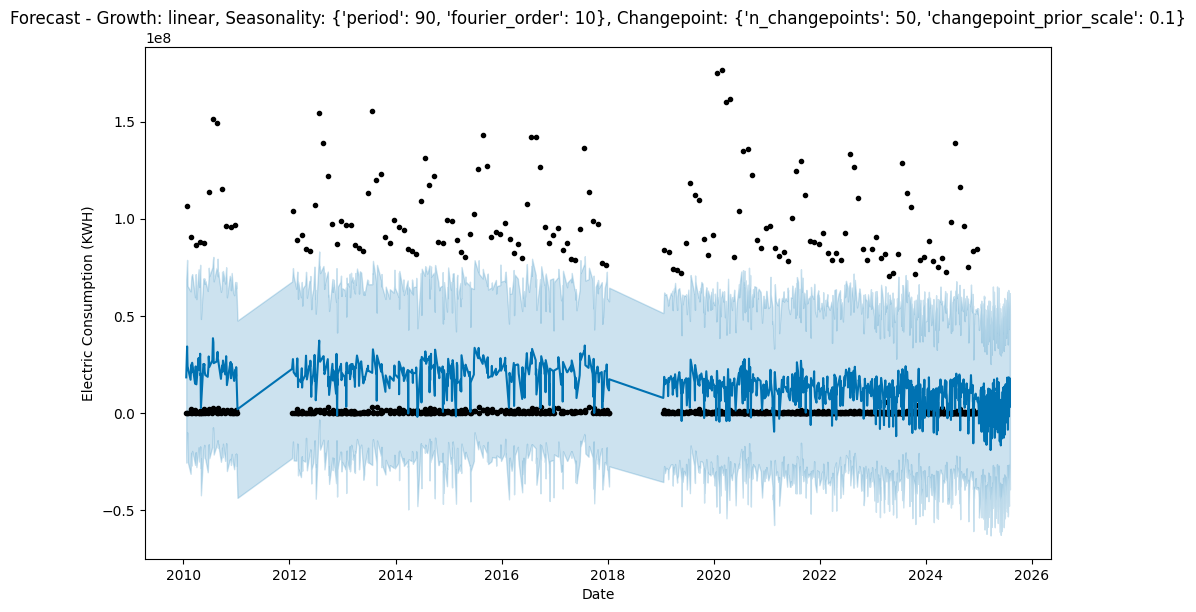

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/ohoztd6t.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/jwmdr954.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=7461', 'data', 'file=/tmp/tmp4ptzph50/ohoztd6t.json', 'init=/tmp/tmp4ptzph50/jwmdr954.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model1nt4331q/prophet_model-20250509194503.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:03 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:03 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  1.695180e+07 -2.666479e+07  6.231311e+07
1244 2025-07-25  1.834087e+07 -2.668617e+07  6.213362e+07
1245 2025-07-26 -2.568709e+05 -4.666408e+07  4.340336e+07
1246 2025-07-27 -1.805215e+06 -4.785498e+07  4.321659e+07
1247 2025-07-28  1.410032e+07 -3.027442e+07  5.478440e+07
1248 2025-07-29  1.323769e+07 -3.339849e+07  5.824253e+07
1249 2025-07-30  8.518902e+06 -3.815996e+07  5.360759e+07
1250 2025-07-31  1.406087e+07 -3.229466e+07  5.835791e+07
1251 2025-08-01  1.785837e+07 -2.733603e+07  6.165911e+07
1252 2025-08-02  3.171612e+06 -3.932700e+07  5.060016e+07
Training model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


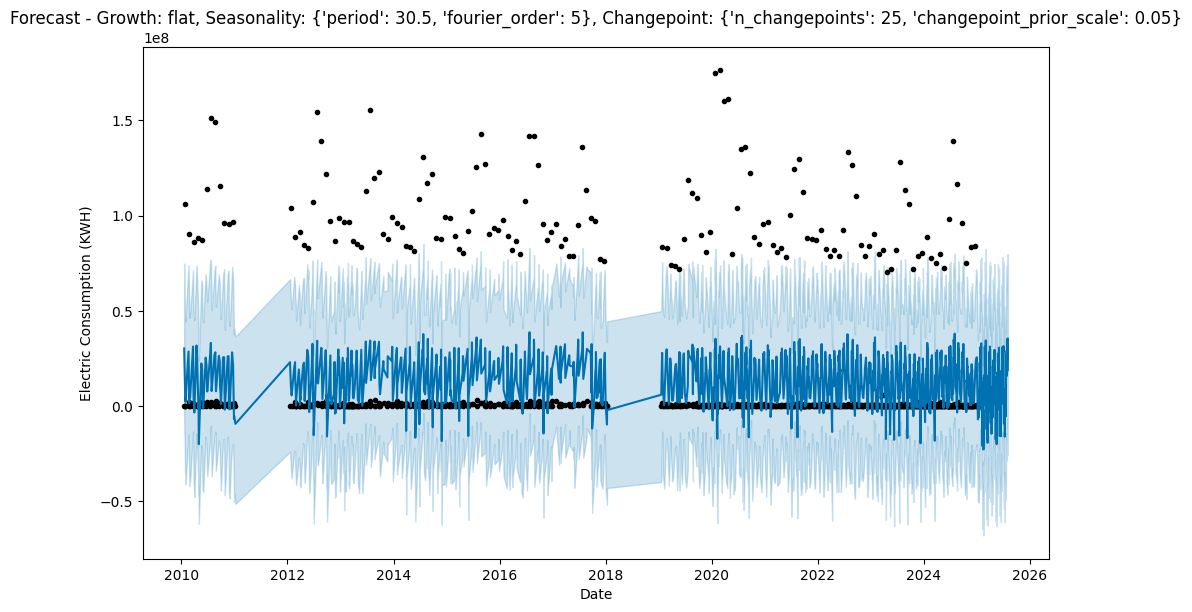

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/d70nh_o2.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/gifbt1cc.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=61443', 'data', 'file=/tmp/tmp4ptzph50/d70nh_o2.json', 'init=/tmp/tmp4ptzph50/gifbt1cc.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model8_ryrx4p/prophet_model-20250509194503.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:03 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:03 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.516548e+07 -1.791231e+07  6.974093e+07
1244 2025-07-25  2.908461e+07 -1.421942e+07  7.368406e+07
1245 2025-07-26  1.582510e+07 -2.771178e+07  5.973591e+07
1246 2025-07-27  1.800181e+07 -2.863919e+07  6.108726e+07
1247 2025-07-28  3.485031e+07 -1.080997e+07  7.497476e+07
1248 2025-07-29  2.909218e+07 -1.154923e+07  7.275341e+07
1249 2025-07-30  2.384685e+07 -1.680319e+07  6.718218e+07
1250 2025-07-31  3.136961e+07 -1.211807e+07  7.426670e+07
1251 2025-08-01  3.548918e+07 -6.444580e+06  7.989327e+07
1252 2025-08-02  1.880044e+07 -2.580454e+07  6.058138e+07
Training model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


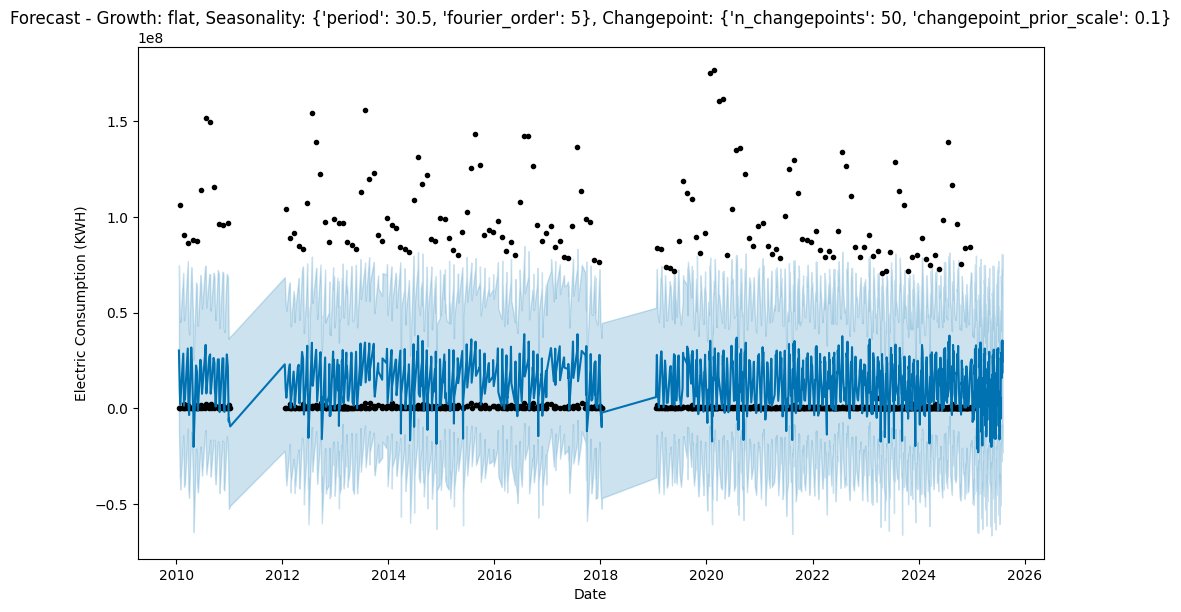

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/me8jcqry.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/b3gqh5uv.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=60128', 'data', 'file=/tmp/tmp4ptzph50/me8jcqry.json', 'init=/tmp/tmp4ptzph50/b3gqh5uv.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelyh28ex_l/prophet_model-20250509194504.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:04 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:04 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.516548e+07 -1.897850e+07  6.740679e+07
1244 2025-07-25  2.908461e+07 -1.476043e+07  7.257244e+07
1245 2025-07-26  1.582510e+07 -2.648615e+07  5.984213e+07
1246 2025-07-27  1.800181e+07 -2.767288e+07  6.067336e+07
1247 2025-07-28  3.485031e+07 -8.378279e+06  8.059840e+07
1248 2025-07-29  2.909218e+07 -1.593377e+07  7.239735e+07
1249 2025-07-30  2.384685e+07 -2.158410e+07  6.924652e+07
1250 2025-07-31  3.136961e+07 -1.199429e+07  7.505561e+07
1251 2025-08-01  3.548918e+07 -8.917778e+06  8.038929e+07
1252 2025-08-02  1.880044e+07 -2.299954e+07  6.502482e+07
Training model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


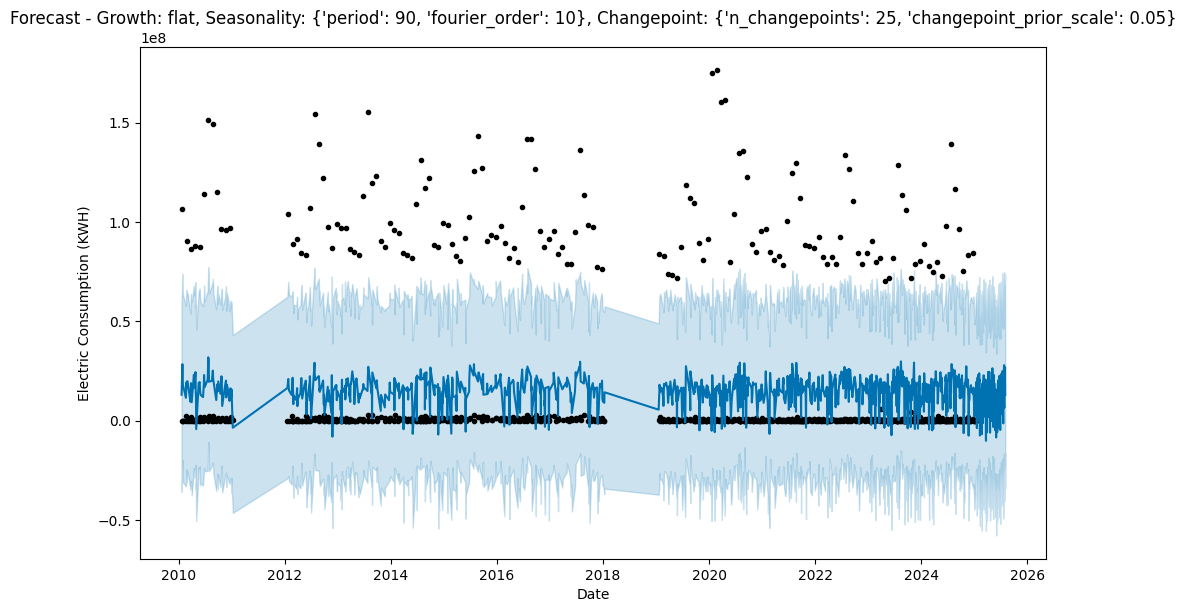

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/clwx6uyu.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/rkasgj7p.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=23407', 'data', 'file=/tmp/tmp4ptzph50/clwx6uyu.json', 'init=/tmp/tmp4ptzph50/rkasgj7p.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelf9nvv0g8/prophet_model-20250509194504.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:04 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:05 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.648225e+07 -1.747595e+07  7.308181e+07
1244 2025-07-25  2.787957e+07 -1.698322e+07  7.470859e+07
1245 2025-07-26  9.879932e+06 -3.416614e+07  5.261833e+07
1246 2025-07-27  6.360895e+06 -4.054117e+07  4.815097e+07
1247 2025-07-28  2.354922e+07 -2.449935e+07  7.261231e+07
1248 2025-07-29  2.228311e+07 -2.200699e+07  6.847163e+07
1249 2025-07-30  1.829098e+07 -2.621347e+07  6.798836e+07
1250 2025-07-31  2.316594e+07 -2.417600e+07  7.045717e+07
1251 2025-08-01  2.687291e+07 -1.618451e+07  7.374296e+07
1252 2025-08-02  1.280732e+07 -3.419613e+07  5.666395e+07
Training model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


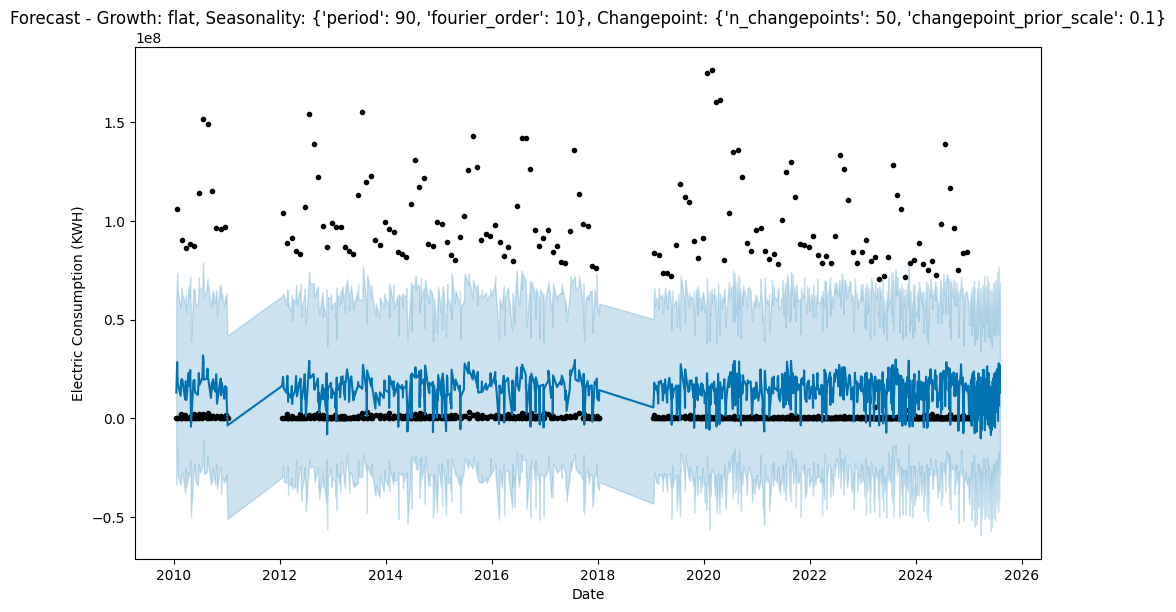

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/nrvw0pl3.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/mjz4jynh.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=85960', 'data', 'file=/tmp/tmp4ptzph50/nrvw0pl3.json', 'init=/tmp/tmp4ptzph50/mjz4jynh.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelrga5gx8x/prophet_model-20250509194505.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:05 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:05 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.648225e+07 -2.148279e+07  6.966982e+07
1244 2025-07-25  2.787957e+07 -1.940838e+07  7.665196e+07
1245 2025-07-26  9.879932e+06 -3.517393e+07  5.384991e+07
1246 2025-07-27  6.360895e+06 -4.189802e+07  5.353986e+07
1247 2025-07-28  2.354922e+07 -2.167662e+07  6.942062e+07
1248 2025-07-29  2.228311e+07 -2.463484e+07  6.657707e+07
1249 2025-07-30  1.829098e+07 -2.614166e+07  6.392873e+07
1250 2025-07-31  2.316594e+07 -1.959937e+07  6.912783e+07
1251 2025-08-01  2.687291e+07 -1.911248e+07  6.853780e+07
1252 2025-08-02  1.280732e+07 -2.849928e+07  5.672783e+07
Training model: Growth=logistic, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


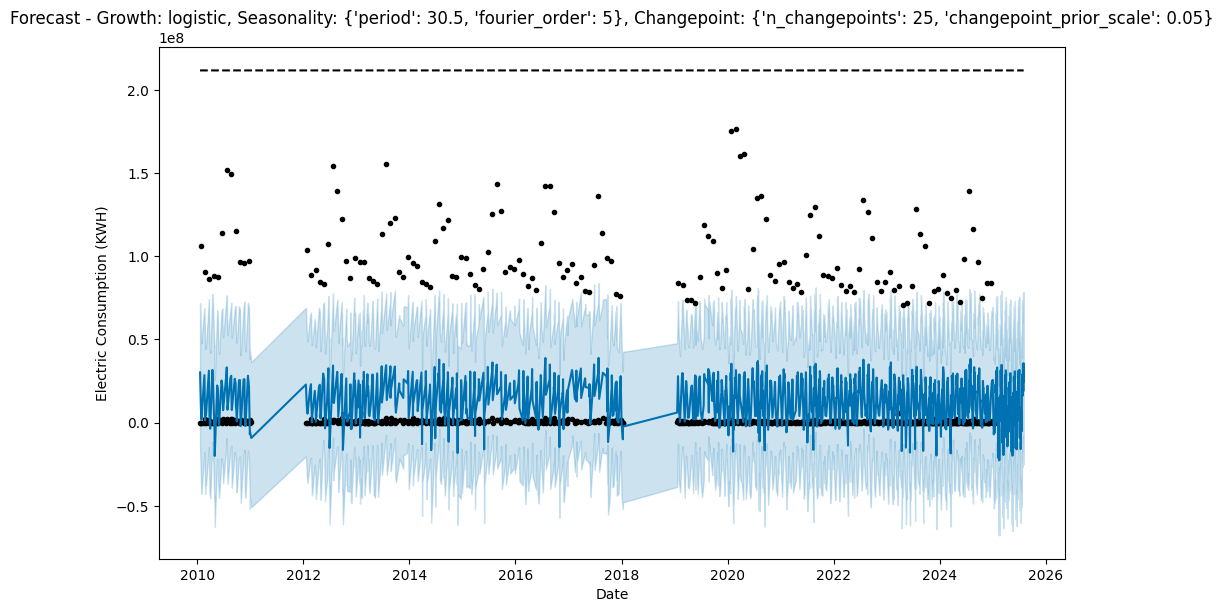

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/o7_bj86z.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/j2fd2isd.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=83291', 'data', 'file=/tmp/tmp4ptzph50/o7_bj86z.json', 'init=/tmp/tmp4ptzph50/j2fd2isd.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelesrn654u/prophet_model-20250509194513.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:13 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:13 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.517326e+07 -1.969842e+07  6.752677e+07
1244 2025-07-25  2.908296e+07 -1.606030e+07  7.345139e+07
1245 2025-07-26  1.618156e+07 -2.639934e+07  6.031979e+07
1246 2025-07-27  1.804235e+07 -2.570675e+07  6.305159e+07
1247 2025-07-28  3.509848e+07 -8.330002e+06  7.747514e+07
1248 2025-07-29  2.930885e+07 -1.698435e+07  7.429383e+07
1249 2025-07-30  2.400211e+07 -1.903351e+07  7.066994e+07
1250 2025-07-31  3.151362e+07 -9.403313e+06  7.775807e+07
1251 2025-08-01  3.568005e+07 -9.593337e+06  7.849029e+07
1252 2025-08-02  1.932920e+07 -2.489578e+07  6.371088e+07
Training model: Growth=logistic, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


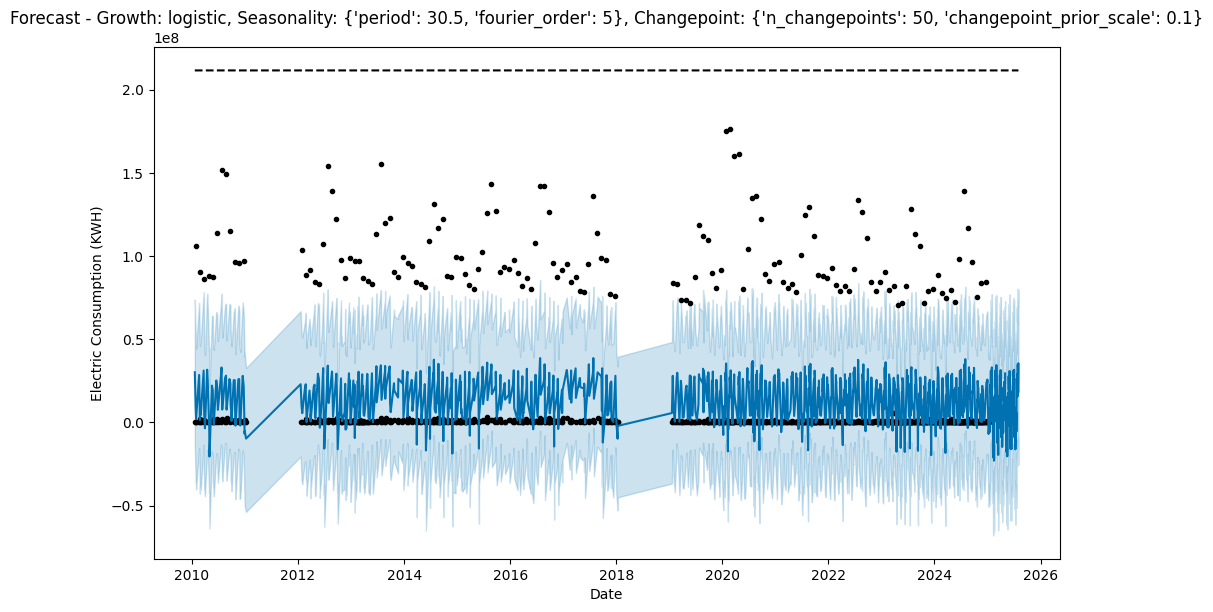

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/btsn8515.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/tddt17cw.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=53567', 'data', 'file=/tmp/tmp4ptzph50/btsn8515.json', 'init=/tmp/tmp4ptzph50/tddt17cw.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelgfj_tqiy/prophet_model-20250509194521.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:21 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:21 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.523576e+07 -1.607756e+07  7.040495e+07
1244 2025-07-25  2.913739e+07 -1.319527e+07  7.348940e+07
1245 2025-07-26  1.552073e+07 -2.604585e+07  6.015803e+07
1246 2025-07-27  1.779813e+07 -2.494504e+07  5.960845e+07
1247 2025-07-28  3.476231e+07 -1.016794e+07  8.040467e+07
1248 2025-07-29  2.903195e+07 -1.474454e+07  7.703673e+07
1249 2025-07-30  2.386805e+07 -1.988786e+07  6.888289e+07
1250 2025-07-31  3.145970e+07 -1.317620e+07  7.570023e+07
1251 2025-08-01  3.554765e+07 -8.920844e+06  7.975146e+07
1252 2025-08-02  1.850212e+07 -2.535625e+07  6.110723e+07
Training model: Growth=logistic, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


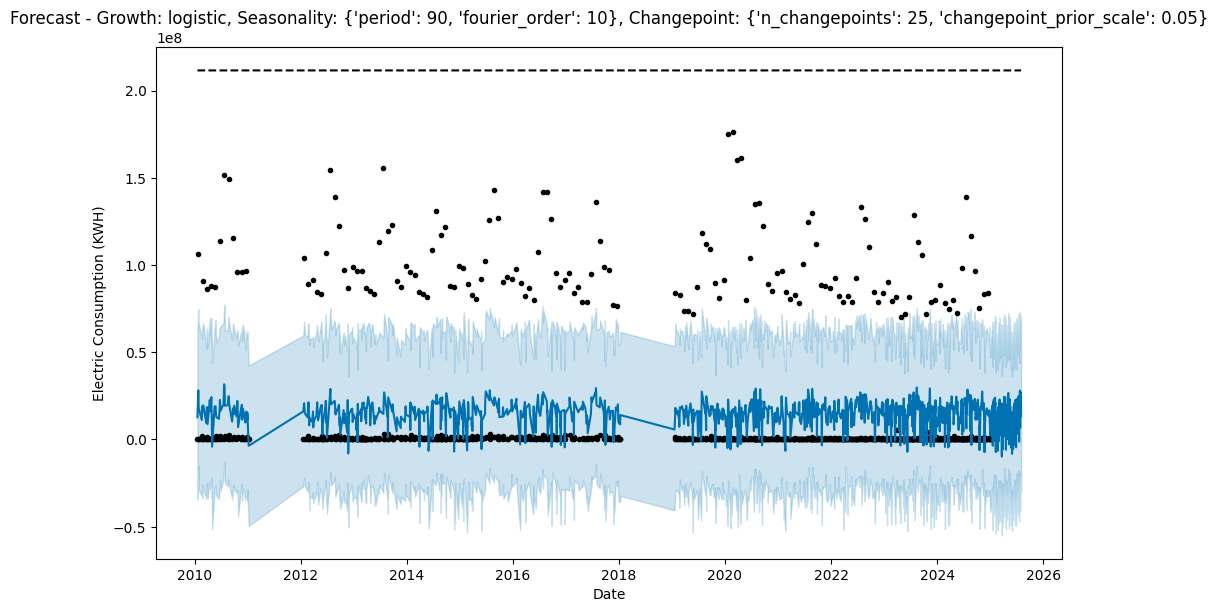

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/uxi5giu0.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/iv6x3h3v.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=83699', 'data', 'file=/tmp/tmp4ptzph50/uxi5giu0.json', 'init=/tmp/tmp4ptzph50/iv6x3h3v.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model6iz_8erh/prophet_model-20250509194530.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:30 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.656153e+07 -2.358207e+07  7.101354e+07
1244 2025-07-25  2.801760e+07 -1.892216e+07  7.326177e+07
1245 2025-07-26  1.039772e+07 -3.807447e+07  5.711633e+07
1246 2025-07-27  6.766382e+06 -4.094641e+07  5.084916e+07
1247 2025-07-28  2.376896e+07 -2.092893e+07  6.923655e+07
1248 2025-07-29  2.246625e+07 -2.240402e+07  6.583850e+07
1249 2025-07-30  1.849807e+07 -3.038938e+07  6.397345e+07
1250 2025-07-31  2.334531e+07 -2.227668e+07  7.017905e+07
1251 2025-08-01  2.706718e+07 -1.872307e+07  7.085980e+07
1252 2025-08-02  1.335003e+07 -2.929586e+07  5.664608e+07
Training model: Growth=logistic, Seasonality={'period': 90, 'fourier_order': 10}, Changepoint={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


19:45:30 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


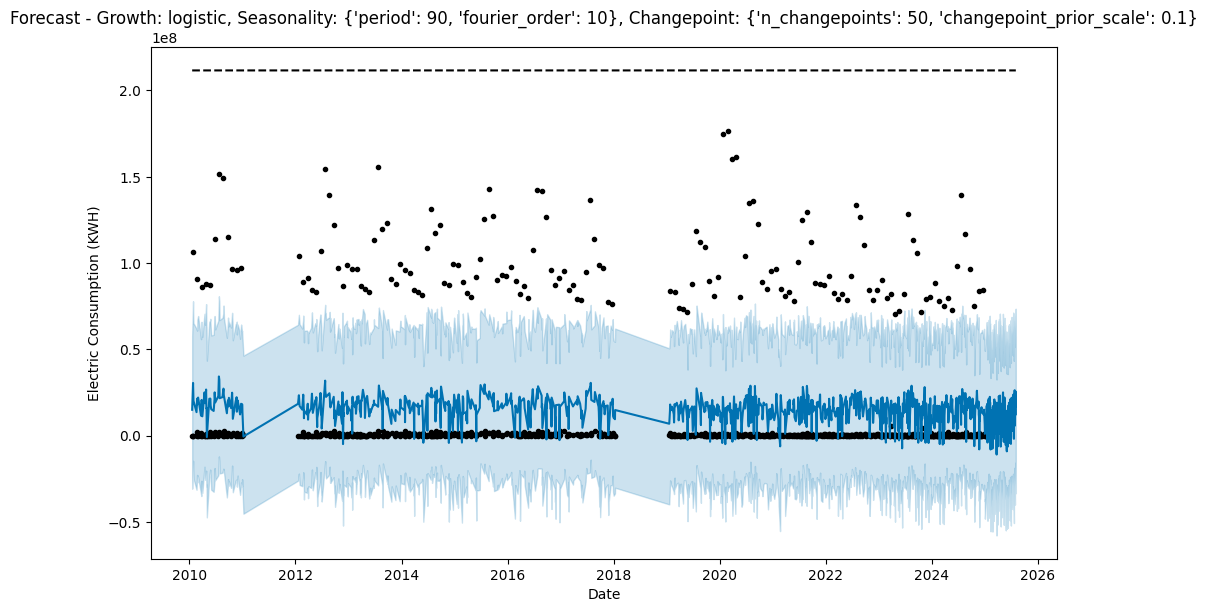

📋 Predicted Forecast (last 10 rows):
             ds          yhat    yhat_lower    yhat_upper
1243 2025-07-24  2.475483e+07 -1.987844e+07  6.922808e+07
1244 2025-07-25  2.627641e+07 -1.853960e+07  7.034661e+07
1245 2025-07-26  9.218018e+06 -3.557192e+07  5.727794e+07
1246 2025-07-27  5.766447e+06 -3.999508e+07  5.162213e+07
1247 2025-07-28  2.200936e+07 -2.280439e+07  6.742509e+07
1248 2025-07-29  2.085153e+07 -2.650621e+07  6.486091e+07
1249 2025-07-30  1.667737e+07 -2.901965e+07  6.099682e+07
1250 2025-07-31  2.166854e+07 -2.490588e+07  6.478679e+07
1251 2025-08-01  2.548185e+07 -1.558103e+07  7.349388e+07
1252 2025-08-02  1.231833e+07 -3.340072e+07  5.766814e+07


In [ ]:
from prophet import Prophet
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Assume df (with columns 'ds' and 'y') is already prepared

# If using logistic growth, you must set a 'cap' value
cap_value = df['y'].max() * 1.2  # set cap slightly above max usage
df['cap'] = cap_value  # needed only for logistic

# Tuning parameter sets
growth_options = ['linear', 'flat', 'logistic']
seasonality_settings = [
    {'period': 30.5, 'fourier_order': 5},
    {'period': 90, 'fourier_order': 10}
]
changepoint_settings = [
    {'n_changepoints': 25, 'changepoint_prior_scale': 0.05},
    {'n_changepoints': 50, 'changepoint_prior_scale': 0.1}
]

# Set forecast horizon (for example 200 days for daily)
forecast_horizon = 200

# Loop through all combinations
for growth in growth_options:
    for seasonality in seasonality_settings:
        for changepoint in changepoint_settings:
            print("="*60)
            print(f"Training model: Growth={growth}, Seasonality={seasonality}, Changepoint={changepoint}")
            print("="*60)

            df_model = df.copy()
            if growth == 'logistic':
                df_model['cap'] = cap_value

            # Initialize model
            model = Prophet(
                growth=growth,
                daily_seasonality=False,
                n_changepoints=changepoint['n_changepoints'],
                changepoint_prior_scale=changepoint['changepoint_prior_scale']
            )

            # Add custom seasonality
            model.add_seasonality(
                name='custom',
                period=seasonality['period'],
                fourier_order=seasonality['fourier_order']
            )

            # Fit model
            model.fit(df_model)

            # Forecast future
            future = model.make_future_dataframe(periods=forecast_horizon, freq='D')
            if growth == 'logistic':
                future['cap'] = cap_value
            forecast = model.predict(future)

            # Plot forecast
            model.plot(forecast)
            plt.title(f"Forecast - Growth: {growth}, Seasonality: {seasonality}, Changepoint: {changepoint}")
            plt.xlabel("Date")
            plt.ylabel("Electric Consumption (KWH)")
            plt.grid()
            plt.show()

            # Print forecast table
            print("📋 Predicted Forecast (last 10 rows):")
            print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(10))


## 📏 Task 4: Evaluate Model Performance

In [ ]:
train_pred = model.predict(df)
y_true = df['y']
y_pred = train_pred['yhat']

mae = mean_absolute_error(y_true, y_pred)
mape = mean_absolute_percentage_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2%}")
print(f"R²: {r2:.2f}")

MAE: 24679481.18
MAPE: 551784230564340130906112.00%
R²: 0.04


## Extra Credit: Borough-wise Forecasting

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/0k2g0ozl.json


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/kp2_376i.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=95185', 'data', 'file=/tmp/tmp4ptzph50/0k2g0ozl.json', 'init=/tmp/tmp4ptzph50/kp2_376i.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelwwc8qeek/prophet_model-20250509194538.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:38 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:39 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


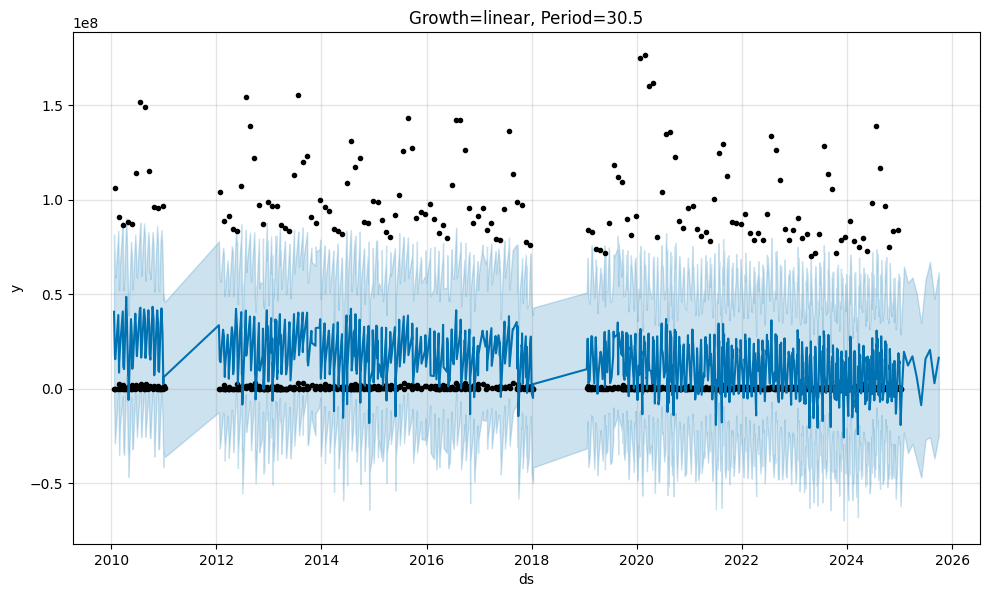

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/_jqtf7wz.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/rxs1205u.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=77560', 'data', 'file=/tmp/tmp4ptzph50/_jqtf7wz.json', 'init=/tmp/tmp4ptzph50/rxs1205u.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelztuvr1rd/prophet_model-20250509194539.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:39 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:39 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


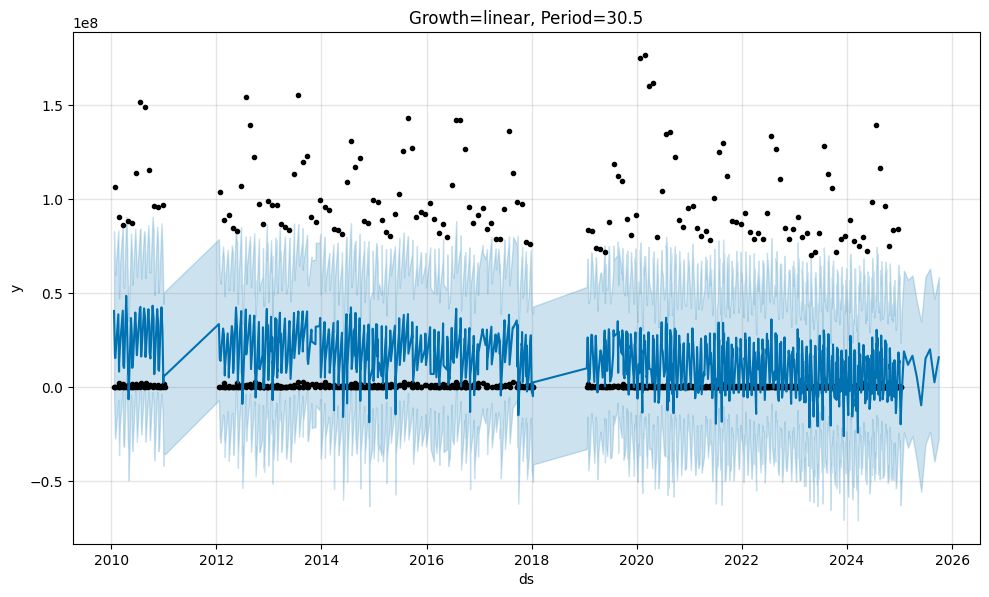

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/4m1swj6n.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/t4pmgmux.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=97269', 'data', 'file=/tmp/tmp4ptzph50/4m1swj6n.json', 'init=/tmp/tmp4ptzph50/t4pmgmux.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model0tun5has/prophet_model-20250509194539.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:39 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:40 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


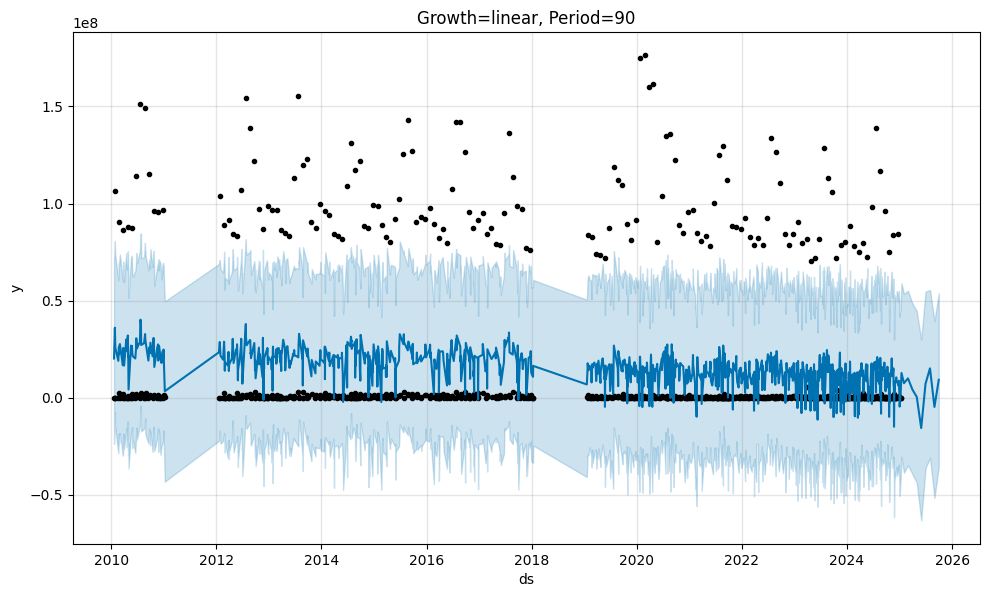

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/jsn0bz0t.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/a25m3i_y.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=97143', 'data', 'file=/tmp/tmp4ptzph50/jsn0bz0t.json', 'init=/tmp/tmp4ptzph50/a25m3i_y.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelu9620_8t/prophet_model-20250509194540.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:40 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:40 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


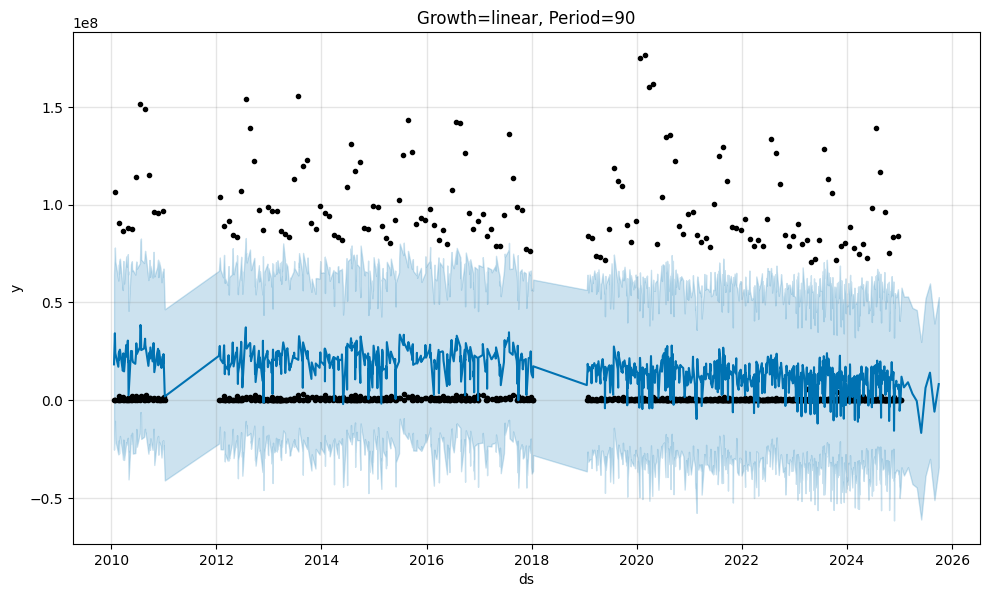

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/gm8ps2a8.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/fjvc2wl_.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=6849', 'data', 'file=/tmp/tmp4ptzph50/gm8ps2a8.json', 'init=/tmp/tmp4ptzph50/fjvc2wl_.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelvtfrj5tg/prophet_model-20250509194540.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:40 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:40 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


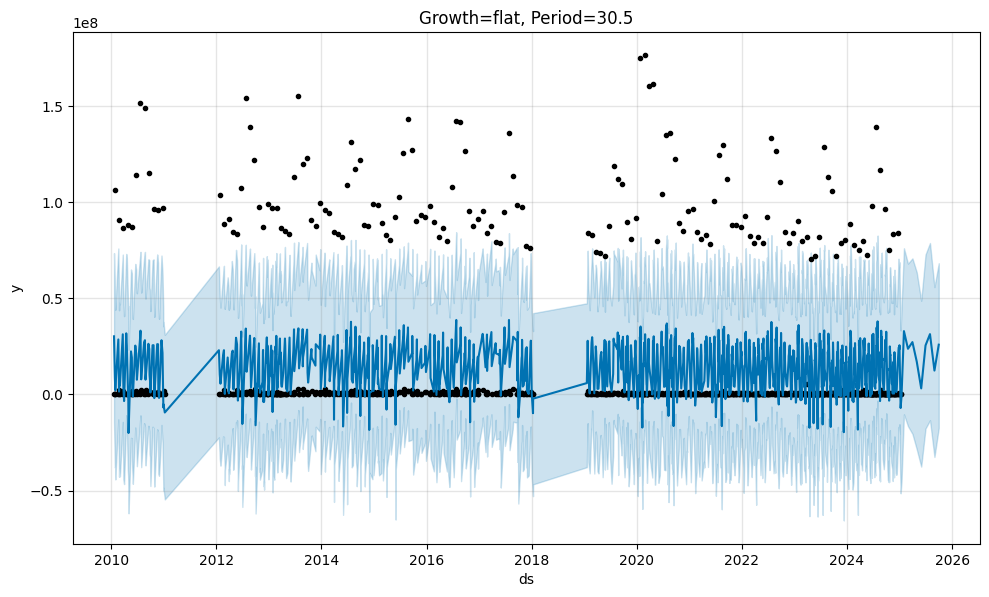

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/u4a0q2rg.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/oubug3fd.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=79579', 'data', 'file=/tmp/tmp4ptzph50/u4a0q2rg.json', 'init=/tmp/tmp4ptzph50/oubug3fd.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelkzzn2ari/prophet_model-20250509194541.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:41 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:41 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


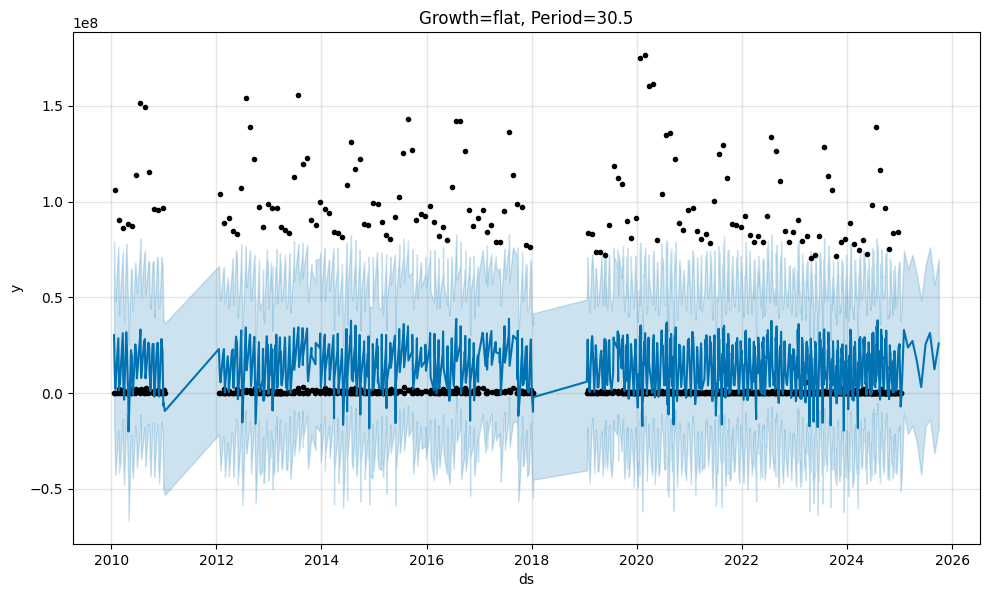

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/1fkwi84o.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/g0uft7se.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=7533', 'data', 'file=/tmp/tmp4ptzph50/1fkwi84o.json', 'init=/tmp/tmp4ptzph50/g0uft7se.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelpnlzcq42/prophet_model-20250509194541.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:41 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:41 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


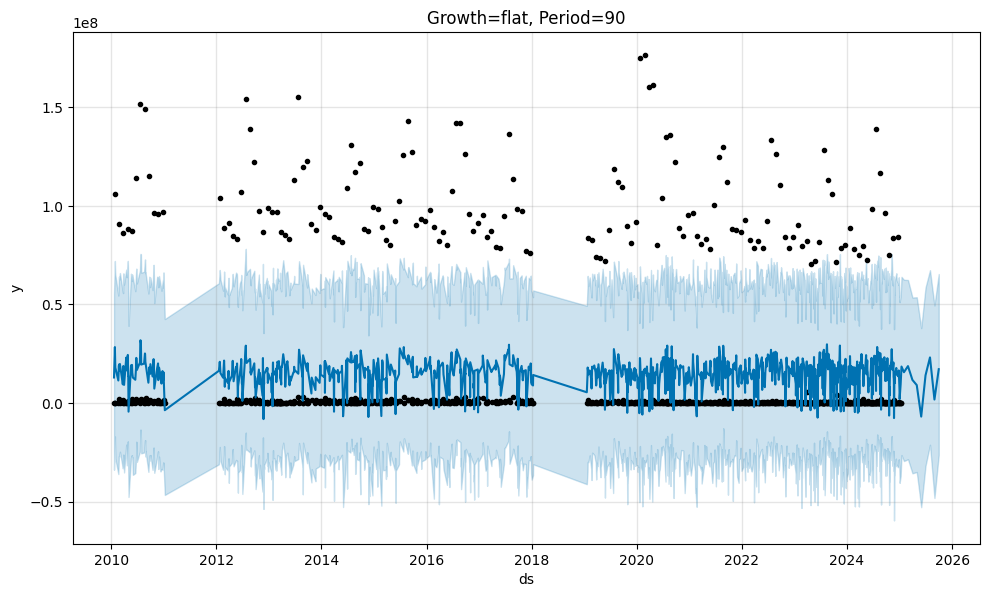

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/1yaxttkx.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/l515uzut.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=89009', 'data', 'file=/tmp/tmp4ptzph50/1yaxttkx.json', 'init=/tmp/tmp4ptzph50/l515uzut.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model4apzbkiy/prophet_model-20250509194542.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:42 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:42 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


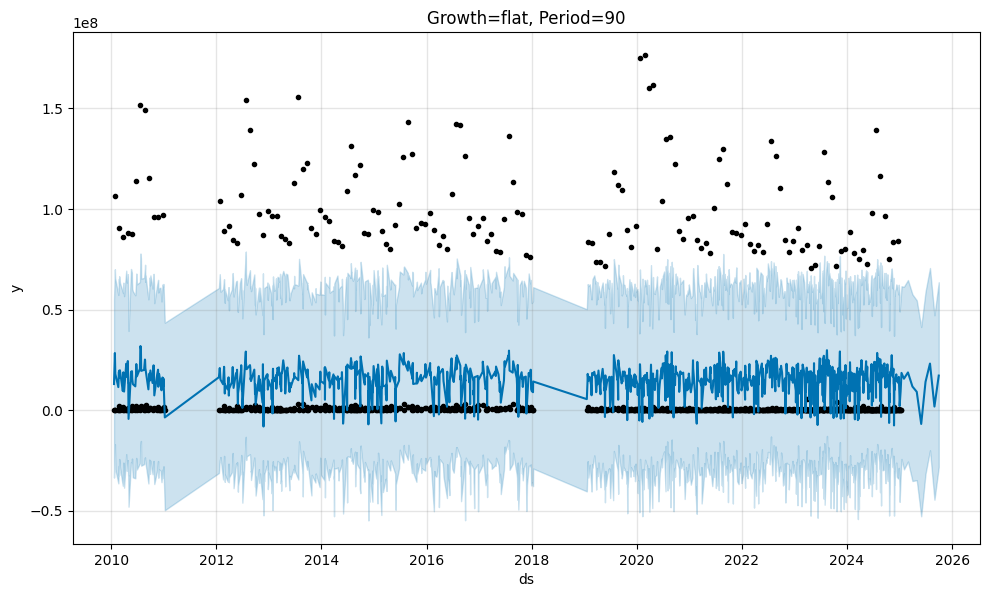

In [ ]:
growth_options = ['linear', 'flat']
seasonality_settings = [{'period': 30.5, 'fourier_order': 5}, {'period': 90, 'fourier_order': 10}]
changepoint_settings = [{'n_changepoints': 25, 'changepoint_prior_scale': 0.05}, {'n_changepoints': 50, 'changepoint_prior_scale': 0.1}]

for growth in growth_options:
    for seasonality in seasonality_settings:
        for changepoint in changepoint_settings:
            print(f"Model: Growth={growth}, Seasonality={seasonality}, Changepoints={changepoint}")
            model = Prophet(
                growth=growth,
                daily_seasonality=False,
                n_changepoints=changepoint['n_changepoints'],
                changepoint_prior_scale=changepoint['changepoint_prior_scale']
            )
            model.add_seasonality(name='custom', period=seasonality['period'], fourier_order=seasonality['fourier_order'])
            model.fit(df)

            # Change freq='M' to freq='ME' to avoid the deprecation warning when time_unit == 'M'
            future = model.make_future_dataframe(periods=max(forecast_periods), freq='ME' if time_unit == 'M' else time_unit)
            forecast = model.predict(future)

            model.plot(forecast)
            plt.title(f"Growth={growth}, Period={seasonality['period']}")
            plt.show()


DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/bimdn8s2.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/sqi7ypmt.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=45268', 'data', 'file=/tmp/tmp4ptzph50/bimdn8s2.json', 'init=/tmp/tmp4ptzph50/sqi7ypmt.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model_vae392e/prophet_model-20250509194542.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:42 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:42 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


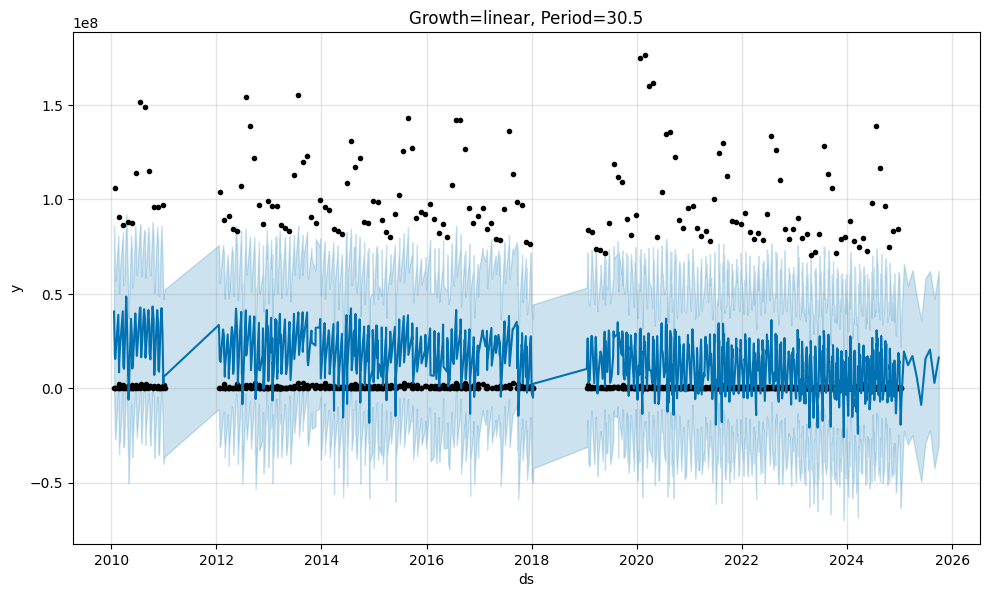

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/mwqyr5qq.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/eikob84b.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=59959', 'data', 'file=/tmp/tmp4ptzph50/mwqyr5qq.json', 'init=/tmp/tmp4ptzph50/eikob84b.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelyq5teo7z/prophet_model-20250509194543.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:43 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:43 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


MAPE: 4706405852096207781888.0000, RMSE: 33723732.1401


Model: Growth=linear, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


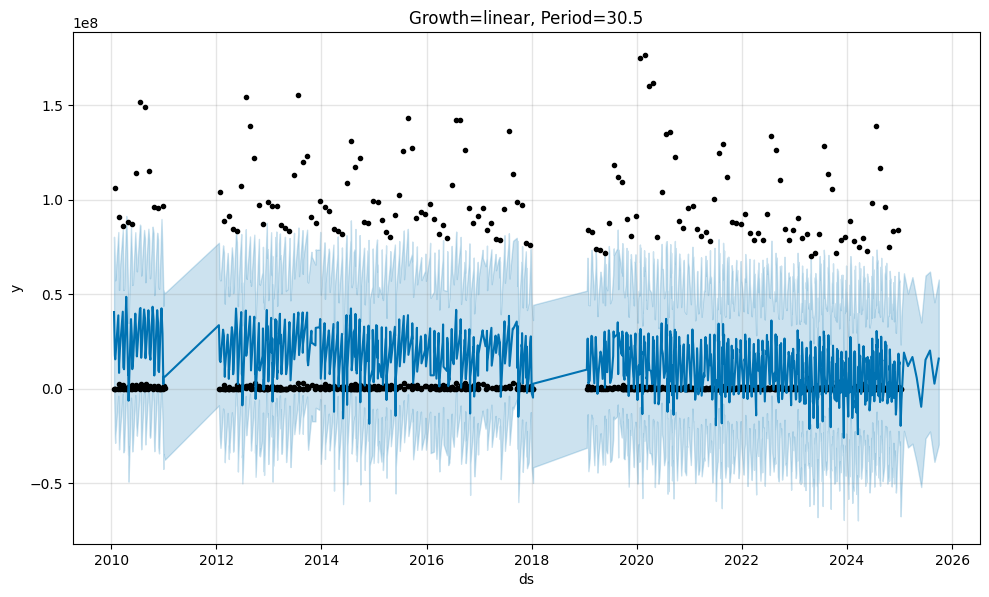

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/bs7cpj7_.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/_jpl9aqi.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=57725', 'data', 'file=/tmp/tmp4ptzph50/bs7cpj7_.json', 'init=/tmp/tmp4ptzph50/_jpl9aqi.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelfryg6vzo/prophet_model-20250509194543.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:43 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:43 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


MAPE: 4726185245484625428480.0000, RMSE: 33720478.7915


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


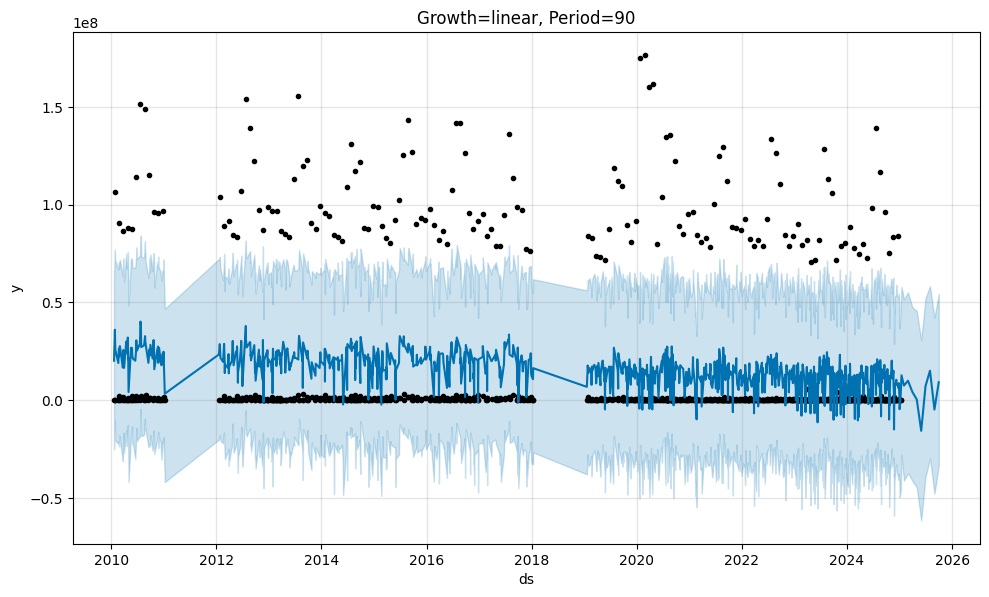

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/zniseroh.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/psjhlor8.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=67111', 'data', 'file=/tmp/tmp4ptzph50/zniseroh.json', 'init=/tmp/tmp4ptzph50/psjhlor8.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelp8tkz4zd/prophet_model-20250509194544.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:44 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


MAPE: 4634684192687160033280.0000, RMSE: 35280034.4079


Model: Growth=linear, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


19:45:44 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


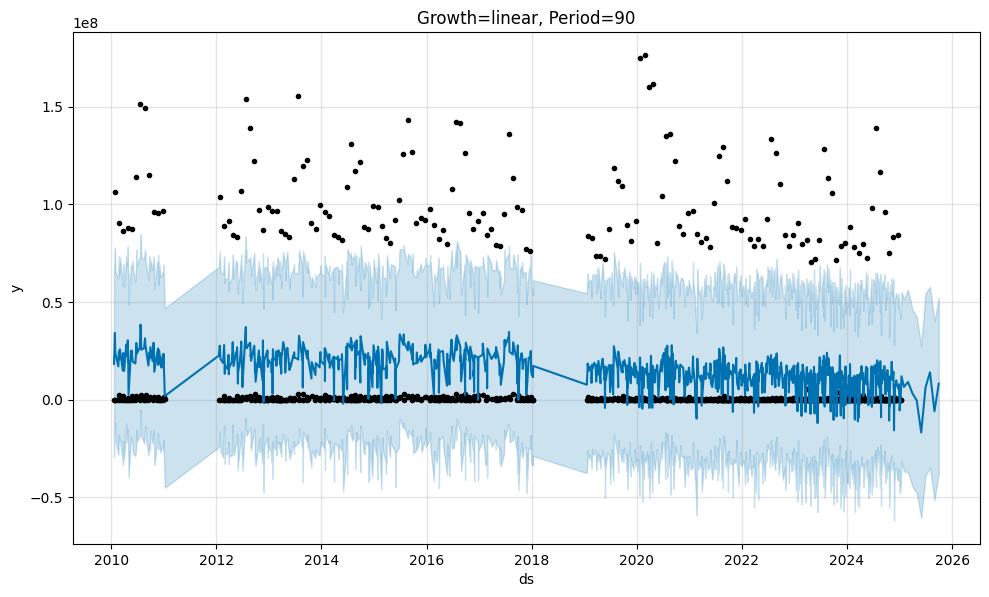

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/y35o2h1k.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/pqvp71no.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=92064', 'data', 'file=/tmp/tmp4ptzph50/y35o2h1k.json', 'init=/tmp/tmp4ptzph50/pqvp71no.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelnau_jc_4/prophet_model-20250509194544.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:44 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:44 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


MAPE: 4546453843695752445952.0000, RMSE: 35257900.0907


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


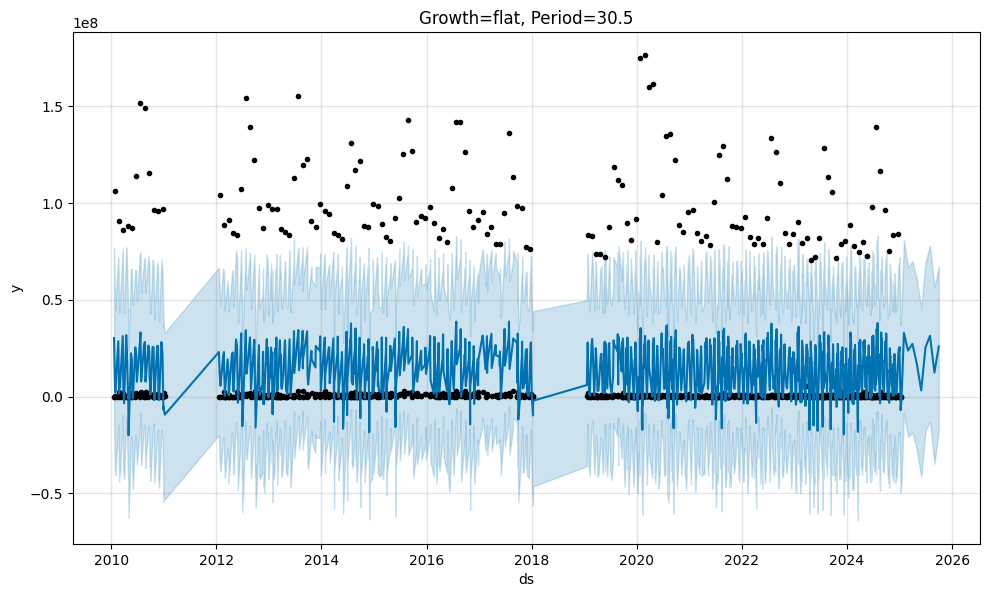

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/gyzqeq09.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/t2povdk0.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=54891', 'data', 'file=/tmp/tmp4ptzph50/gyzqeq09.json', 'init=/tmp/tmp4ptzph50/t2povdk0.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelr7iw_wcy/prophet_model-20250509194545.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:45 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:45 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


MAPE: 4662729451956673708032.0000, RMSE: 34234426.0464


Model: Growth=flat, Seasonality={'period': 30.5, 'fourier_order': 5}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


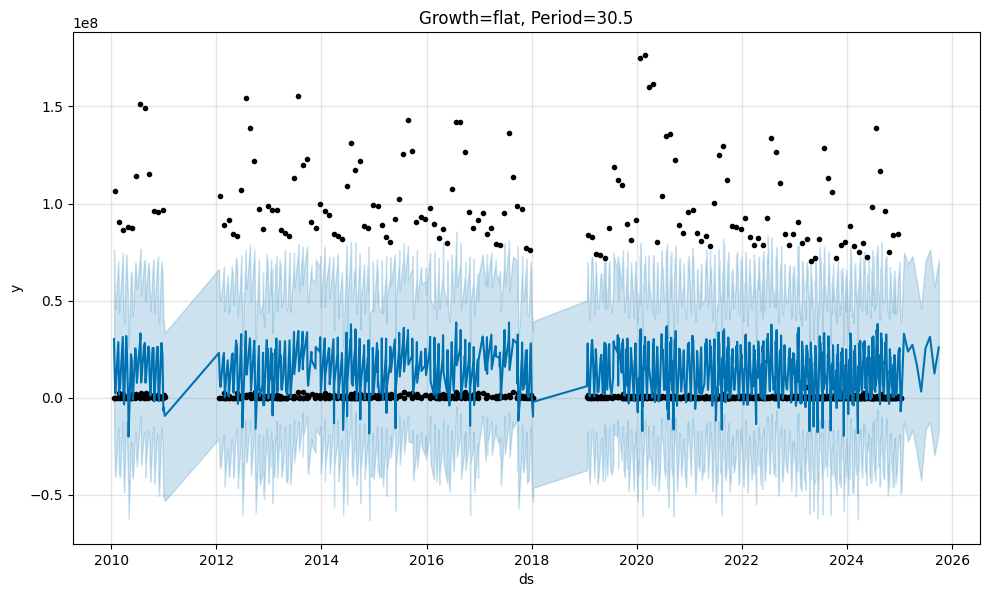

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/_ioqbzac.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/t0nlfri1.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=75933', 'data', 'file=/tmp/tmp4ptzph50/_ioqbzac.json', 'init=/tmp/tmp4ptzph50/t0nlfri1.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_model6x0d3bna/prophet_model-20250509194546.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:46 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing


MAPE: 4662729451956673708032.0000, RMSE: 34234426.0464


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 25, 'changepoint_prior_scale': 0.05}


19:45:46 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


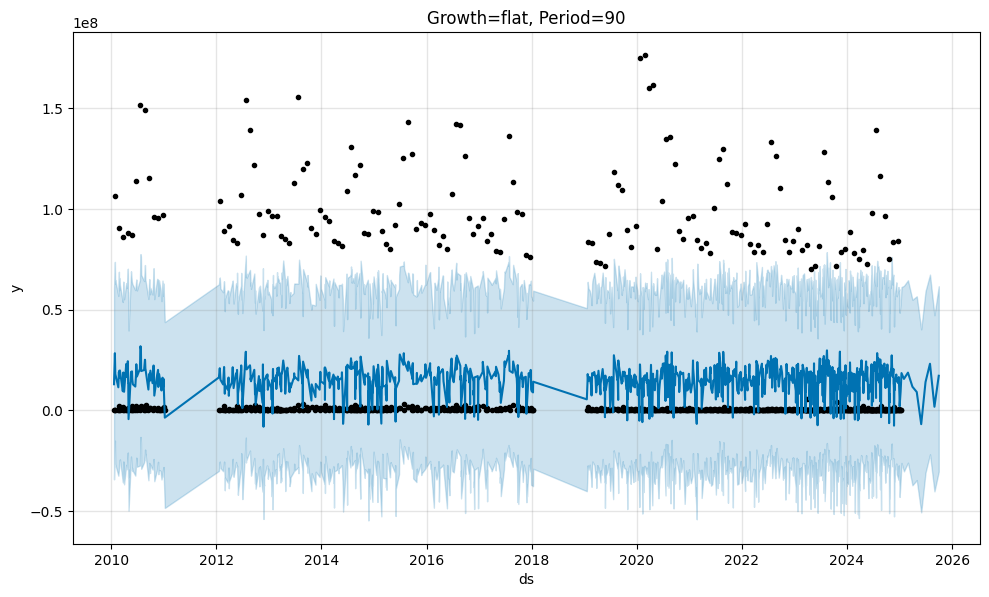

DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/1kuxqrg7.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp4ptzph50/lniaxops.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=93455', 'data', 'file=/tmp/tmp4ptzph50/1kuxqrg7.json', 'init=/tmp/tmp4ptzph50/lniaxops.json', 'output', 'file=/tmp/tmp4ptzph50/prophet_modelngd8sm8n/prophet_model-20250509194546.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
19:45:46 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
19:45:46 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


MAPE: 5631203432696570183680.0000, RMSE: 35648860.2605


Model: Growth=flat, Seasonality={'period': 90, 'fourier_order': 10}, Changepoints={'n_changepoints': 50, 'changepoint_prior_scale': 0.1}


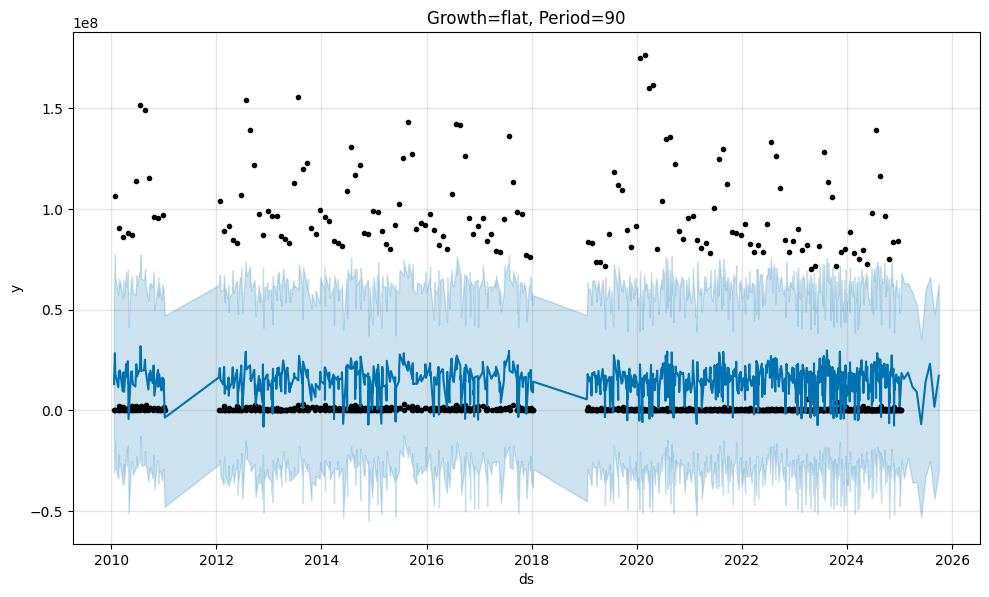

MAPE: 5631203432696570183680.0000, RMSE: 35648860.2605




In [ ]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from math import sqrt

# Define the function to calculate MAPE and RMSE
def calculate_error_metrics(actual, predicted):
    mape = mean_absolute_percentage_error(actual, predicted)
    rmse = sqrt(mean_squared_error(actual, predicted))
    return mape, rmse

growth_options = ['linear', 'flat']
seasonality_settings = [{'period': 30.5, 'fourier_order': 5}, {'period': 90, 'fourier_order': 10}]
changepoint_settings = [{'n_changepoints': 25, 'changepoint_prior_scale': 0.05}, {'n_changepoints': 50, 'changepoint_prior_scale': 0.1}]

for growth in growth_options:
    for seasonality in seasonality_settings:
        for changepoint in changepoint_settings:
            print(f"Model: Growth={growth}, Seasonality={seasonality}, Changepoints={changepoint}")

            # Train the Prophet model with the current configuration
            model = Prophet(
                growth=growth,
                daily_seasonality=False,
                n_changepoints=changepoint['n_changepoints'],
                changepoint_prior_scale=changepoint['changepoint_prior_scale']
            )
            model.add_seasonality(name='custom', period=seasonality['period'], fourier_order=seasonality['fourier_order'])
            model.fit(df)

            # Generate future data frame
            future = model.make_future_dataframe(periods=max(forecast_periods), freq='ME' if time_unit == 'M' else time_unit)
            forecast = model.predict(future)

            # Plot the forecast
            model.plot(forecast)
            plt.title(f"Growth={growth}, Period={seasonality['period']}")
            plt.show()

            # Calculate error metrics on the forecasted data
            actual = df['y'][-len(forecast):].values  # Actual data (last known values)
            predicted = forecast['yhat'][:len(actual)].values  # Predicted values (from forecast)

            # Ensure the lengths match (in case of any mismatch)
            if len(actual) == len(predicted):
                mape, rmse = calculate_error_metrics(actual, predicted)
                print(f"MAPE: {mape:.4f}, RMSE: {rmse:.4f}")
            else:
                print("Error: Mismatch in the length of actual and predicted data")

            print("\n")
